# Otara High-Water-Risk Classification

This notebook reconstructs and validates the Otara hourly dataset, defines a 24-hour high-water-risk target, engineers hydrological features, and compares Random Forest and XGBoost classifiers using chronological training, validation, and test periods.

## 1. Data Loading and Station Audit

In [1]:
# Code cell 1 - Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

In [2]:
# Code cell 2 - File paths
file_paths = {
    "rain_primary": Path(
        r"C:\Users\kgeet\Downloads\649940.csv"
    ),
    "rain_support": Path(
        r"C:\Users\kgeet\Downloads\649818.csv"
    ),
    "discharge_primary": Path(
        r"C:\Users\kgeet\Downloads\8208 (1).csv"
    ),
    "level_primary": Path(
        r"C:\Users\kgeet\Downloads\8208 (2).csv"
    )
}

for dataset_name, file_path in file_paths.items():
    print(
        dataset_name,
        "-",
        file_path.name,
        "- exists:",
        file_path.exists()
    )

rain_primary - 649940.csv - exists: True
rain_support - 649818.csv - exists: True
discharge_primary - 8208 (1).csv - exists: True
level_primary - 8208 (2).csv - exists: True


In [3]:
# Code cell 3 - Reusable loader
def load_gauge_data(file_path, value_name):
    """
    Load an Environment Auckland hourly gauge export.

    The first row contains dataset metadata and the second row contains
    the actual column headers.
    """
    data = pd.read_csv(
        file_path,
        skiprows=1
    )

    if data.shape[1] != 3:
        raise ValueError(
            f"{file_path.name} contains {data.shape[1]} columns; "
            "three columns were expected."
        )

    data = data.iloc[:, :3].copy()

    data.columns = [
        "timestamp",
        "interval_end",
        value_name
    ]

    data["timestamp"] = pd.to_datetime(
        data["timestamp"],
        errors="coerce"
    )

    data["interval_end"] = pd.to_datetime(
        data["interval_end"],
        errors="coerce"
    )

    data[value_name] = pd.to_numeric(
        data[value_name],
        errors="coerce"
    )

    data = (
        data
        .dropna(subset=["timestamp"])
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    return data

In [4]:
# Code cell 4 — Load and initially inspect the four datasets
rain_primary = load_gauge_data(
    file_paths["rain_primary"],
    "rainfall_primary_mm"
)

rain_support = load_gauge_data(
    file_paths["rain_support"],
    "rainfall_support_mm"
)

discharge_primary = load_gauge_data(
    file_paths["discharge_primary"],
    "discharge_m3s"
)

level_primary = load_gauge_data(
    file_paths["level_primary"],
    "water_level_m"
)

datasets = {
    "rain_primary_649940": (
        rain_primary,
        "rainfall_primary_mm"
    ),
    "rain_support_649818": (
        rain_support,
        "rainfall_support_mm"
    ),
    "discharge_8208": (
        discharge_primary,
        "discharge_m3s"
    ),
    "water_level_8208": (
        level_primary,
        "water_level_m"
    )
}

audit_results = []

for dataset_name, (data, value_column) in datasets.items():
    audit_results.append({
        "dataset": dataset_name,
        "rows": len(data),
        "unique_timestamps": data["timestamp"].nunique(),
        "duplicate_timestamps": data[
            "timestamp"
        ].duplicated().sum(),
        "beginning": data["timestamp"].min(),
        "ending": data["timestamp"].max(),
        "missing_values": data[value_column].isna().sum(),
        "negative_values": (
            data[value_column] < 0
        ).sum()
    })

audit_table = pd.DataFrame(
    audit_results
).set_index("dataset")

display(audit_table)

,rows,unique_timestamps,duplicate_timestamps,beginning,ending,missing_values,negative_values
dataset,,,,,,,
rain_primary_649940,92776,92766,10,2015-06-02 19:00:00,2026-01-01 00:00:00,3832,0
rain_support_649818,76912,76904,8,2015-01-01 01:00:00,2023-10-10 08:00:00,909,0
discharge_8208,101040,101040,0,2015-01-01 00:00:00,2026-07-11 23:00:00,162,0
water_level_8208,101040,101040,0,2015-01-01 00:00:00,2026-07-11 23:00:00,11,0


## 2. Duplicate Resolution and Hourly Alignment

Duplicate timestamps are checked before merging. Identical duplicate observations are collapsed into one row. If duplicate rows contain conflicting non-missing rainfall values, the code stops for manual inspection.

In [5]:
# Inspect duplicated rainfall timestamps before resolving them

def show_duplicate_timestamps(data, dataset_name):
    duplicate_rows = data[
        data.duplicated("timestamp", keep=False)
    ].sort_values("timestamp")

    print(
        f"{dataset_name}: "
        f"{duplicate_rows['timestamp'].nunique()} duplicated timestamps, "
        f"{len(duplicate_rows)} involved rows"
    )

    display(duplicate_rows)


show_duplicate_timestamps(
    rain_primary,
    "Primary rainfall - 649940"
)

show_duplicate_timestamps(
    rain_support,
    "Supporting rainfall - 649818"
)

Primary rainfall - 649940: 10 duplicated timestamps, 20 involved rows


,timestamp,interval_end,rainfall_primary_mm
5093,2016-01-01,NaT,NaN
5094,2016-01-01,NaT,0.0
13878,2017-01-01,NaT,0.0
13879,2017-01-01,NaT,NaN
22639,2018-01-01,NaT,0.0
22640,2018-01-01,NaT,NaN
31400,2019-01-01,NaT,NaN
31401,2019-01-01,NaT,NaN
40162,2020-01-01,NaT,NaN
40161,2020-01-01,NaT,NaN


Supporting rainfall - 649818: 8 duplicated timestamps, 16 involved rows


,timestamp,interval_end,rainfall_support_mm
8759,2016-01-01,NaT,0.0
8760,2016-01-01,NaT,NaN
17544,2017-01-01,NaT,NaN
17545,2017-01-01,NaT,0.0
26305,2018-01-01,NaT,0.0
26306,2018-01-01,NaT,NaN
35066,2019-01-01,NaT,NaN
35067,2019-01-01,NaT,NaN
43827,2020-01-01,NaT,0.0
43828,2020-01-01,NaT,NaN


In [6]:
# Resolve duplicated rainfall timestamps safely

def resolve_duplicate_timestamps(data, value_column, dataset_name):
    data = data.copy()

    # Check for timestamps containing different non-missing measurements
    distinct_valid_values = (
        data.groupby("timestamp")[value_column]
        .apply(lambda values: values.dropna().nunique())
    )

    conflicting_timestamps = distinct_valid_values[
        distinct_valid_values > 1
    ].index

    if len(conflicting_timestamps) > 0:
        display(
            data[
                data["timestamp"].isin(conflicting_timestamps)
            ].sort_values("timestamp")
        )

        raise ValueError(
            f"{dataset_name} contains conflicting non-missing "
            "measurements at duplicated timestamps."
        )

    rows_before = len(data)

    # Put valid measurements before missing measurements
    data["_measurement_available"] = data[value_column].notna()

    data = (
        data
        .sort_values(
            ["timestamp", "_measurement_available"],
            ascending=[True, False]
        )
        .drop_duplicates("timestamp", keep="first")
        .drop(columns="_measurement_available")
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    print(
        f"{dataset_name}: "
        f"{rows_before:,} rows -> {len(data):,} unique hourly rows"
    )

    return data


rain_primary = resolve_duplicate_timestamps(
    rain_primary,
    "rainfall_primary_mm",
    "Primary rainfall — 649940"
)

rain_support = resolve_duplicate_timestamps(
    rain_support,
    "rainfall_support_mm",
    "Supporting rainfall — 649818"
)

Primary rainfall — 649940: 92,776 rows -> 92,766 unique hourly rows
Supporting rainfall — 649818: 76,912 rows -> 76,904 unique hourly rows


In [7]:
# Verify rainfall datasets after duplicate resolution

duplicate_resolution_check = pd.DataFrame({
    "dataset": [
        "rain_primary_649940",
        "rain_support_649818"
    ],
    "rows": [
        len(rain_primary),
        len(rain_support)
    ],
    "unique_timestamps": [
        rain_primary["timestamp"].nunique(),
        rain_support["timestamp"].nunique()
    ],
    "duplicate_timestamps": [
        rain_primary["timestamp"].duplicated().sum(),
        rain_support["timestamp"].duplicated().sum()
    ],
    "missing_values": [
        rain_primary["rainfall_primary_mm"].isna().sum(),
        rain_support["rainfall_support_mm"].isna().sum()
    ]
}).set_index("dataset")

display(duplicate_resolution_check)

,rows,unique_timestamps,duplicate_timestamps,missing_values
dataset,,,,
rain_primary_649940,92766,92766,0,3822
rain_support_649818,76904,76904,0,901


## 3. Create the Hourly Otara Base Dataset

A continuous hourly timeline is created for the common study period. Rainfall station 649940 is used as the primary source, while station 649818 is used only when the primary measurement is missing. Remaining missing measurements are preserved rather than interpreted as zero rainfall. River discharge and water level are obtained from station 8208. No measurements from another catchment are used to substitute missing river observations.

In [8]:
# Define the fixed study period used for Otara

study_start = pd.Timestamp("2015-01-01 01:00:00")
study_end = pd.Timestamp("2026-01-01 00:00:00")

hourly_timeline = pd.DataFrame({
    "timestamp": pd.date_range(
        start=study_start,
        end=study_end,
        freq="h"
    )
})

print("Study period:", study_start, "to", study_end)
print("Expected hourly rows:", len(hourly_timeline))

Study period: 2015-01-01 01:00:00 to 2026-01-01 00:00:00
Expected hourly rows: 96432


In [9]:
# Merge rainfall, discharge and water-level measurements

otara_base = (
    hourly_timeline
    .merge(
        rain_primary[["timestamp", "rainfall_primary_mm"]],
        on="timestamp",
        how="left"
    )
    .merge(
        rain_support[["timestamp", "rainfall_support_mm"]],
        on="timestamp",
        how="left"
    )
    .merge(
        discharge_primary[["timestamp", "discharge_m3s"]],
        on="timestamp",
        how="left"
    )
    .merge(
        level_primary[["timestamp", "water_level_m"]],
        on="timestamp",
        how="left"
    )
)

# Primary rainfall first; supporting rainfall only where primary is missing
otara_base["rainfall_mm"] = (
    otara_base["rainfall_primary_mm"]
    .combine_first(otara_base["rainfall_support_mm"])
)

otara_base["rainfall_source"] = np.select(
    [
        otara_base["rainfall_primary_mm"].notna(),
        (
            otara_base["rainfall_primary_mm"].isna()
            & otara_base["rainfall_support_mm"].notna()
        )
    ],
    [
        "649940_primary",
        "649818_support"
    ],
    default="missing"
)

otara_base["rainfall_substituted"] = (
    otara_base["rainfall_source"] == "649818_support"
)

# River variables use station 8208 only
otara_base["discharge_source"] = np.where(
    otara_base["discharge_m3s"].notna(),
    "8208_primary",
    "missing"
)

otara_base["water_level_source"] = np.where(
    otara_base["water_level_m"].notna(),
    "8208_primary",
    "missing"
)

otara_base["discharge_substituted"] = False
otara_base["water_level_substituted"] = False

# Retain the same base structure used for Mahurangi
otara_base = otara_base[[
    "timestamp",
    "rainfall_mm",
    "rainfall_substituted",
    "rainfall_source",
    "discharge_m3s",
    "water_level_m",
    "discharge_substituted",
    "water_level_substituted",
    "discharge_source",
    "water_level_source"
]]

display(otara_base.head())
print("Otara base shape:", otara_base.shape)

,timestamp,rainfall_mm,rainfall_substituted,rainfall_source,discharge_m3s,water_level_m,discharge_substituted,water_level_substituted,discharge_source,water_level_source
0,2015-01-01 01:00:00,5.951792,True,649818_support,0.972,0.664,False,False,8208_primary,8208_primary
1,2015-01-01 02:00:00,0.980000,True,649818_support,0.805,0.636,False,False,8208_primary,8208_primary
2,2015-01-01 03:00:00,0.490000,True,649818_support,0.603,0.598,False,False,8208_primary,8208_primary
3,2015-01-01 04:00:00,0.000000,True,649818_support,0.451,0.566,False,False,8208_primary,8208_primary
4,2015-01-01 05:00:00,0.000000,True,649818_support,0.366,0.546,False,False,8208_primary,8208_primary


Otara base shape: (96432, 10)


In [10]:
# Audit the merged hourly Otara dataset

base_audit = pd.DataFrame({
    "measurement": [
        "rainfall_mm",
        "discharge_m3s",
        "water_level_m"
    ],
    "available": [
        otara_base["rainfall_mm"].notna().sum(),
        otara_base["discharge_m3s"].notna().sum(),
        otara_base["water_level_m"].notna().sum()
    ],
    "missing": [
        otara_base["rainfall_mm"].isna().sum(),
        otara_base["discharge_m3s"].isna().sum(),
        otara_base["water_level_m"].isna().sum()
    ],
    "availability_percent": [
        otara_base["rainfall_mm"].notna().mean() * 100,
        otara_base["discharge_m3s"].notna().mean() * 100,
        otara_base["water_level_m"].notna().mean() * 100
    ]
}).set_index("measurement")

print("Rainfall source counts:")
display(otara_base["rainfall_source"].value_counts(dropna=False).to_frame("hours"))

print("Merged measurement availability:")
display(base_audit.round(3))

print("Duplicate timestamps:", otara_base["timestamp"].duplicated().sum())
print("Total hourly rows:", len(otara_base))

Rainfall source counts:


,hours
rainfall_source,
649940_primary,88944
649818_support,6809
missing,679


Merged measurement availability:


,available,missing,availability_percent
measurement,,,
rainfall_mm,95753,679,99.296
discharge_m3s,96283,149,99.845
water_level_m,96432,0,100.000


Duplicate timestamps: 0
Total hourly rows: 96432


## 4. Missing-Data Treatment

Supporting rainfall station 649818 recovered 6,809 measurements that were unavailable from primary station 649940. After substitution, 679 rainfall measurements and 149 discharge measurements remain missing. The remaining missing values are not filled with zero or interpolated across the complete dataset. Zero represents a genuine observation for rainfall, while global interpolation could introduce artificial information and temporal leakage. Missingness indicators are retained, and rows requiring unavailable measurements will later be excluded only after feature engineering.

In [11]:
# Preserve the base measurements and record remaining missingness

otara_preprocessed = otara_base.copy()

otara_preprocessed["rainfall_missing"] = (
    otara_preprocessed["rainfall_mm"].isna()
)

otara_preprocessed["discharge_missing"] = (
    otara_preprocessed["discharge_m3s"].isna()
)

otara_preprocessed["water_level_missing"] = (
    otara_preprocessed["water_level_m"].isna()
)

print("Preprocessed dataset shape:", otara_preprocessed.shape)

display(
    otara_preprocessed[[
        "rainfall_missing",
        "discharge_missing",
        "water_level_missing"
    ]]
    .sum()
    .to_frame("missing_hours")
)

Preprocessed dataset shape: (96432, 13)


,missing_hours
rainfall_missing,679
discharge_missing,149
water_level_missing,0


In [12]:
# Summarise consecutive missing-data episodes

def summarise_missing_episodes(data, column):
    missing = data[column].isna()

    if not missing.any():
        return {
            "missing_hours": 0,
            "missing_episodes": 0,
            "longest_episode_hours": 0,
            "median_episode_hours": 0
        }

    episode_group = missing.ne(missing.shift(fill_value=False)).cumsum()

    episode_lengths = (
        missing[missing]
        .groupby(episode_group[missing])
        .size()
    )

    return {
        "missing_hours": int(missing.sum()),
        "missing_episodes": int(len(episode_lengths)),
        "longest_episode_hours": int(episode_lengths.max()),
        "median_episode_hours": float(episode_lengths.median())
    }


missing_episode_audit = pd.DataFrame({
    "rainfall_mm": summarise_missing_episodes(
        otara_preprocessed,
        "rainfall_mm"
    ),
    "discharge_m3s": summarise_missing_episodes(
        otara_preprocessed,
        "discharge_m3s"
    ),
    "water_level_m": summarise_missing_episodes(
        otara_preprocessed,
        "water_level_m"
    )
}).T

display(missing_episode_audit)

,missing_hours,missing_episodes,longest_episode_hours,median_episode_hours
rainfall_mm,679.0,2.0,461.0,339.5
discharge_m3s,149.0,18.0,94.0,2.0
water_level_m,0.0,0.0,0.0,0.0


## 5. Exploratory Analysis

Exploratory analysis is used to understand the distributions, long-term behaviour and seasonal patterns of rainfall, river discharge and water level. Only concise plots directly relevant to feature engineering and flood-risk modelling are included.

In [13]:
# Core measurement dataset used for exploratory analysis

event_analysis = otara_preprocessed[[
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m"
]].copy()

summary_statistics = event_analysis.describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.995]
).T

display(summary_statistics.round(3))

,count,mean,std,min,50%,75%,90%,95%,99%,99.5%,max
rainfall_mm,95753.0,0.146,0.858,0.000,0.000,0.000,0.000,0.520,3.440,5.055,50.311
discharge_m3s,96283.0,0.497,1.629,0.013,0.154,0.391,1.024,1.783,5.486,8.589,69.482
water_level_m,96432.0,0.529,0.137,0.000,0.485,0.552,0.673,0.776,1.075,1.243,2.811


In [14]:
# Create calendar variables for seasonality analysis

seasonality_data = otara_preprocessed[[
    "timestamp",
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m"
]].copy()

seasonality_data["month"] = seasonality_data["timestamp"].dt.month
seasonality_data["hour"] = seasonality_data["timestamp"].dt.hour
seasonality_data["day_of_week"] = (
    seasonality_data["timestamp"].dt.dayofweek
)

print("Event-analysis shape:", event_analysis.shape)
print("Seasonality-data shape:", seasonality_data.shape)

display(seasonality_data.head())

Event-analysis shape: (96432, 3)
Seasonality-data shape: (96432, 7)


,timestamp,rainfall_mm,discharge_m3s,water_level_m,month,hour,day_of_week
0,2015-01-01 01:00:00,5.951792,0.972,0.664,1,1,3
1,2015-01-01 02:00:00,0.980000,0.805,0.636,1,2,3
2,2015-01-01 03:00:00,0.490000,0.603,0.598,1,3,3
3,2015-01-01 04:00:00,0.000000,0.451,0.566,1,4,3
4,2015-01-01 05:00:00,0.000000,0.366,0.546,1,5,3


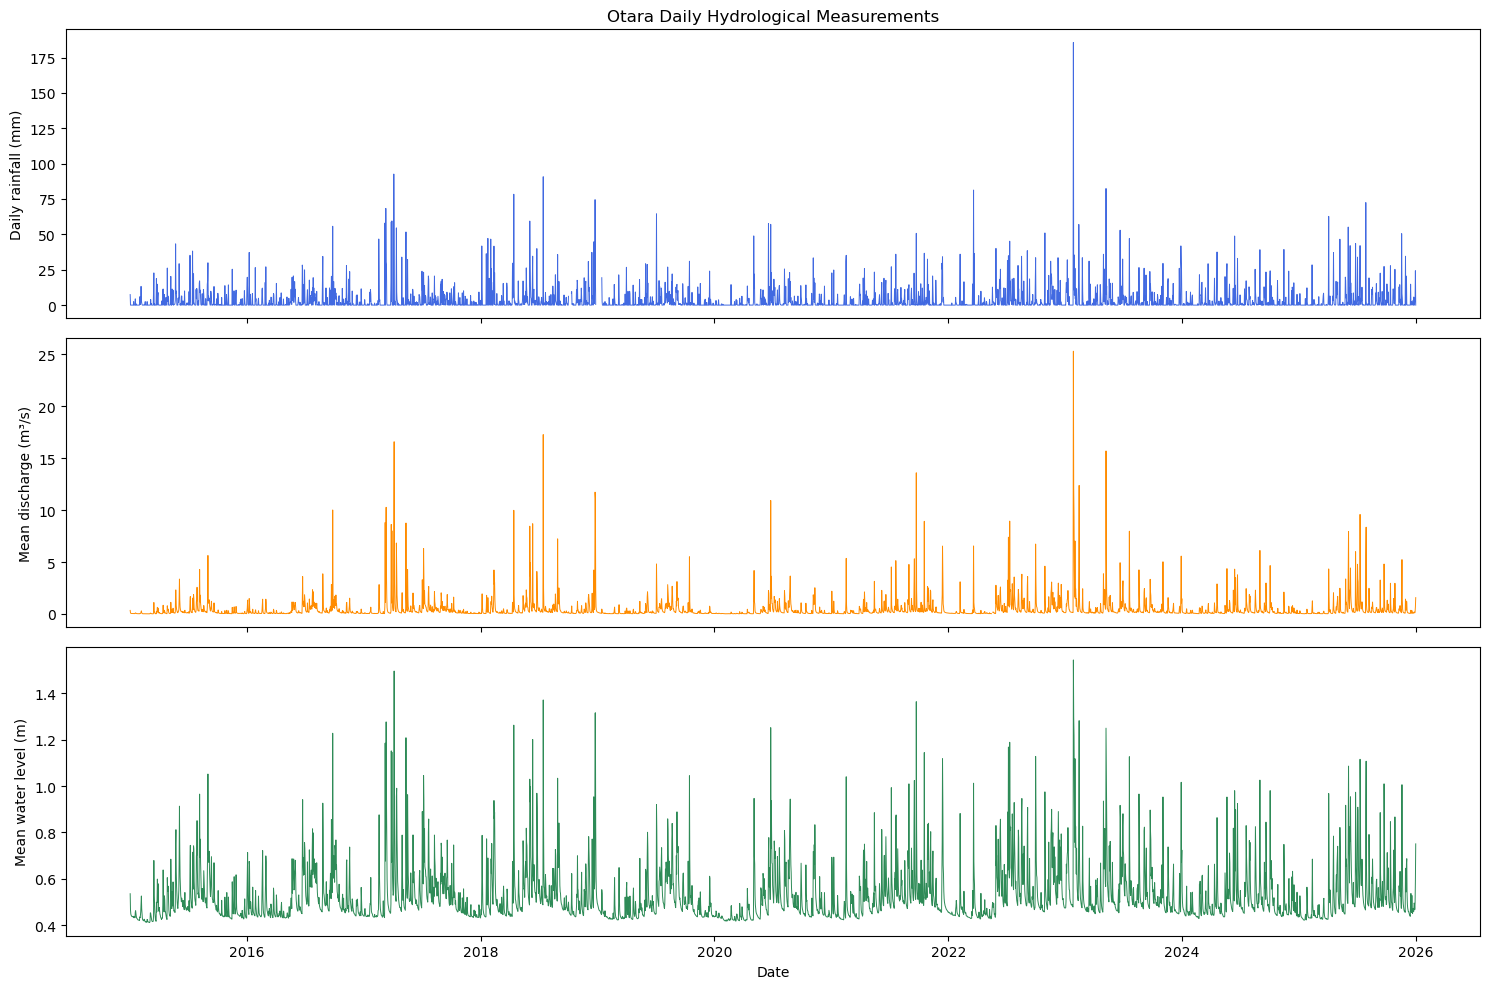

In [15]:
# Daily summaries make the eleven-year time series readable

daily_summary = (
    otara_preprocessed
    .set_index("timestamp")
    .resample("D")
    .agg({
        "rainfall_mm": lambda values: values.sum(min_count=1),
        "discharge_m3s": "mean",
        "water_level_m": "mean"
    })
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 10),
    sharex=True
)

axes[0].plot(
    daily_summary.index,
    daily_summary["rainfall_mm"],
    color="royalblue",
    linewidth=0.7
)
axes[0].set_ylabel("Daily rainfall (mm)")
axes[0].set_title("Otara Daily Hydrological Measurements")

axes[1].plot(
    daily_summary.index,
    daily_summary["discharge_m3s"],
    color="darkorange",
    linewidth=0.7
)
axes[1].set_ylabel("Mean discharge (m³/s)")

axes[2].plot(
    daily_summary.index,
    daily_summary["water_level_m"],
    color="seagreen",
    linewidth=0.7
)
axes[2].set_ylabel("Mean water level (m)")
axes[2].set_xlabel("Date")

plt.tight_layout()
plt.show()

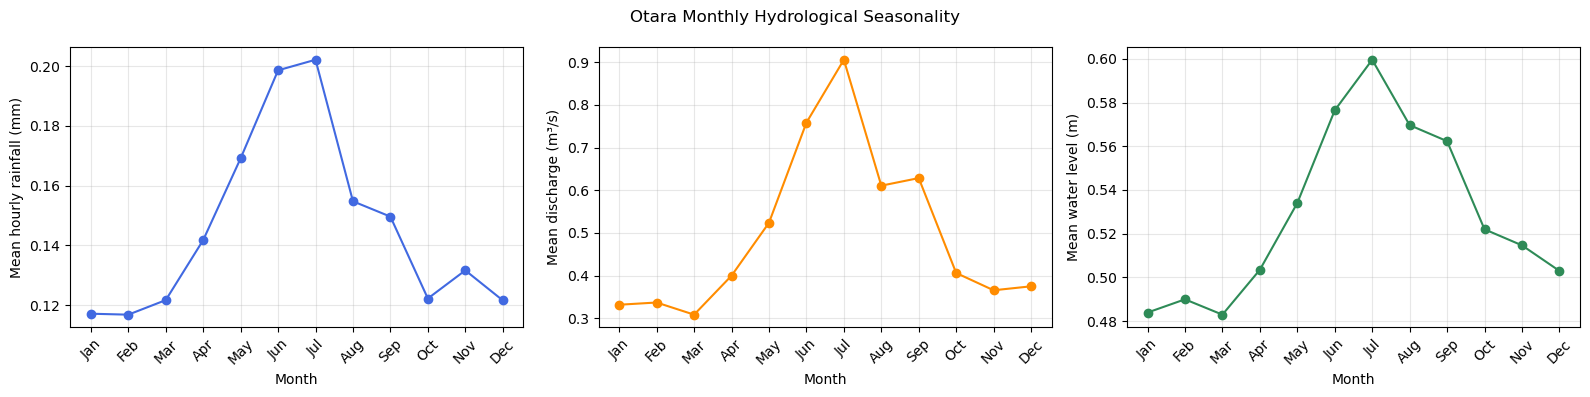

,rainfall_mm,discharge_m3s,water_level_m
month,,,
1,0.117,0.332,0.484
2,0.117,0.337,0.490
3,0.122,0.309,0.483
4,0.142,0.400,0.503
5,0.169,0.524,0.534
6,0.199,0.758,0.576
7,0.202,0.906,0.600
8,0.155,0.611,0.570
9,0.150,0.628,0.562


In [16]:
# Examine recurring monthly patterns

monthly_seasonality = (
    seasonality_data
    .groupby("month")[[
        "rainfall_mm",
        "discharge_m3s",
        "water_level_m"
    ]]
    .mean()
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 4)
)

variables = [
    ("rainfall_mm", "Mean hourly rainfall (mm)", "royalblue"),
    ("discharge_m3s", "Mean discharge (m³/s)", "darkorange"),
    ("water_level_m", "Mean water level (m)", "seagreen")
]

for axis, (column, ylabel, colour) in zip(axes, variables):
    axis.plot(
        monthly_seasonality.index,
        monthly_seasonality[column],
        marker="o",
        color=colour
    )
    axis.set_xticks(range(1, 13))
    axis.set_xticklabels(month_labels, rotation=45)
    axis.set_ylabel(ylabel)
    axis.set_xlabel("Month")
    axis.grid(alpha=0.3)

fig.suptitle("Otara Monthly Hydrological Seasonality")
plt.tight_layout()
plt.show()

display(monthly_seasonality.round(3))

## 6. Chronological Splitting and Target Definition

The dataset is divided chronologically into approximately 70% training, 15% validation and 15% test periods. Random splitting and cross-validation are not used because they could allow future hydrological conditions to influence earlier predictions. High-water risk is defined using the 99.5th percentile of water level calculated from the training period only. At each timestamp, the classification target indicates whether water level exceeds this threshold at any point during the following 24 hours.

In [17]:
# Establish fixed chronological split boundaries

total_hours = len(otara_preprocessed)

train_end_position = int(total_hours * 0.70) - 1
validation_end_position = int(total_hours * 0.85) - 1

train_end_time = otara_preprocessed.loc[
    train_end_position,
    "timestamp"
]

validation_end_time = otara_preprocessed.loc[
    validation_end_position,
    "timestamp"
]

print("Full period:")
print(
    otara_preprocessed["timestamp"].min(),
    "to",
    otara_preprocessed["timestamp"].max()
)

print("\nTraining period ends:", train_end_time)
print("Validation period ends:", validation_end_time)
print("Test period ends:", study_end)

Full period:
2015-01-01 01:00:00 to 2026-01-01 00:00:00

Training period ends: 2022-09-13 14:00:00
Validation period ends: 2024-05-08 07:00:00
Test period ends: 2026-01-01 00:00:00


In [18]:
# Calculate the high-water threshold from training data only

training_water_levels = otara_preprocessed.loc[
    otara_preprocessed["timestamp"] <= train_end_time,
    "water_level_m"
].dropna()

water_level_threshold = training_water_levels.quantile(0.995)

print(
    "Training observations used for threshold:",
    len(training_water_levels)
)

print(
    "Training-only 99.5th percentile water-level threshold:",
    round(water_level_threshold, 4),
    "m"
)

Training observations used for threshold: 67502
Training-only 99.5th percentile water-level threshold: 1.211 m


In [19]:
# Create future water-level observations for hours 1 through 24

prediction_horizon_hours = 24

future_water_levels = pd.concat(
    [
        otara_preprocessed["water_level_m"].shift(-hour)
        for hour in range(1, prediction_horizon_hours + 1)
    ],
    axis=1
)

future_water_levels.columns = [
    f"water_level_plus_{hour}h"
    for hour in range(1, prediction_horizon_hours + 1)
]

model_data = otara_preprocessed.copy()

model_data["future_max_water_level_24h"] = (
    future_water_levels.max(axis=1)
)

# The target is available only when all next 24 hourly levels exist
model_data["target_available"] = (
    future_water_levels.notna().all(axis=1)
)

model_data["flood_risk_next_24h"] = np.where(
    model_data["target_available"],
    (
        model_data["future_max_water_level_24h"]
        >= water_level_threshold
    ).astype(int),
    np.nan
)

print("Model-data shape:", model_data.shape)

display(
    model_data[[
        "timestamp",
        "water_level_m",
        "future_max_water_level_24h",
        "target_available",
        "flood_risk_next_24h"
    ]].tail(30)
)

Model-data shape: (96432, 16)


,timestamp,water_level_m,future_max_water_level_24h,target_available,flood_risk_next_24h
96402,2025-12-30 19:00:00,0.501,0.803,True,0.0
96403,2025-12-30 20:00:00,0.504,0.803,True,0.0
96404,2025-12-30 21:00:00,0.506,0.803,True,0.0
96405,2025-12-30 22:00:00,0.502,0.803,True,0.0
96406,2025-12-30 23:00:00,0.496,0.803,True,0.0
96407,2025-12-31 00:00:00,0.501,0.803,True,0.0
96408,2025-12-31 01:00:00,0.503,0.803,False,NaN
96409,2025-12-31 02:00:00,0.503,0.803,False,NaN
96410,2025-12-31 03:00:00,0.502,0.803,False,NaN
96411,2025-12-31 04:00:00,0.505,0.803,False,NaN


In [20]:
# Identify observations whose full 24-hour target window
# remains inside the same chronological period

target_window_end = (
    model_data["timestamp"]
    + pd.Timedelta(hours=prediction_horizon_hours)
)

train_period_mask = (
    (model_data["timestamp"] <= train_end_time)
    & (target_window_end <= train_end_time)
    & model_data["target_available"]
)

validation_period_mask = (
    (model_data["timestamp"] > train_end_time)
    & (model_data["timestamp"] <= validation_end_time)
    & (target_window_end <= validation_end_time)
    & model_data["target_available"]
)

test_period_mask = (
    (model_data["timestamp"] > validation_end_time)
    & (model_data["timestamp"] <= study_end)
    & (target_window_end <= study_end)
    & model_data["target_available"]
)

target_period_audit = pd.DataFrame({
    "period": ["Training", "Validation", "Test"],
    "eligible_rows_before_feature_removal": [
        train_period_mask.sum(),
        validation_period_mask.sum(),
        test_period_mask.sum()
    ],
    "positive_target_rows": [
        model_data.loc[
            train_period_mask,
            "flood_risk_next_24h"
        ].sum(),
        model_data.loc[
            validation_period_mask,
            "flood_risk_next_24h"
        ].sum(),
        model_data.loc[
            test_period_mask,
            "flood_risk_next_24h"
        ].sum()
    ]
}).set_index("period")

target_period_audit["positive_percentage"] = (
    target_period_audit["positive_target_rows"]
    / target_period_audit["eligible_rows_before_feature_removal"]
    * 100
)

display(target_period_audit.round(3))

,eligible_rows_before_feature_removal,positive_target_rows,positive_percentage
period,,,
Training,67478,1403.0,2.079
Validation,14441,477.0,3.303
Test,14441,406.0,2.811


## 7. Feature Engineering

Lagged rainfall, accumulated rainfall, recent discharge and water-level measurements, rates of change and cyclical time variables are created. All features use information available at or before the prediction timestamp. No future measurements are included as predictors.

In [21]:
# Create hydrological and temporal predictor features

feature_data = model_data.copy()

lag_hours = [1, 2, 3, 6, 12, 24]
rainfall_windows = [3, 6, 12, 24, 48]
change_hours = [1, 3, 6]

# Rainfall lags
for lag in lag_hours:
    feature_data[f"rainfall_lag_{lag}h"] = (
        feature_data["rainfall_mm"].shift(lag)
    )

# Accumulated rainfall, including the current hour
for window in rainfall_windows:
    feature_data[f"rainfall_sum_{window}h"] = (
        feature_data["rainfall_mm"]
        .rolling(window=window, min_periods=window)
        .sum()
    )

# Discharge and water-level lags
for lag in lag_hours:
    feature_data[f"discharge_lag_{lag}h"] = (
        feature_data["discharge_m3s"].shift(lag)
    )

    feature_data[f"water_level_lag_{lag}h"] = (
        feature_data["water_level_m"].shift(lag)
    )

# Recent changes
for period in change_hours:
    feature_data[f"discharge_change_{period}h"] = (
        feature_data["discharge_m3s"]
        - feature_data["discharge_m3s"].shift(period)
    )

    feature_data[f"water_level_change_{period}h"] = (
        feature_data["water_level_m"]
        - feature_data["water_level_m"].shift(period)
    )

# Cyclical time features
feature_data["hour_sin"] = np.sin(
    2 * np.pi * feature_data["timestamp"].dt.hour / 24
)

feature_data["hour_cos"] = np.cos(
    2 * np.pi * feature_data["timestamp"].dt.hour / 24
)

feature_data["month_sin"] = np.sin(
    2 * np.pi * feature_data["timestamp"].dt.month / 12
)

feature_data["month_cos"] = np.cos(
    2 * np.pi * feature_data["timestamp"].dt.month / 12
)

print("Feature-data shape:", feature_data.shape)

Feature-data shape: (96432, 49)


In [22]:
# Define the same predictor structure used for Mahurangi

feature_columns = [
    # Current measurements
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m",

    # Rainfall lags
    "rainfall_lag_1h",
    "rainfall_lag_2h",
    "rainfall_lag_3h",
    "rainfall_lag_6h",
    "rainfall_lag_12h",
    "rainfall_lag_24h",

    # Accumulated rainfall
    "rainfall_sum_3h",
    "rainfall_sum_6h",
    "rainfall_sum_12h",
    "rainfall_sum_24h",
    "rainfall_sum_48h",

    # Discharge lags
    "discharge_lag_1h",
    "discharge_lag_2h",
    "discharge_lag_3h",
    "discharge_lag_6h",
    "discharge_lag_12h",
    "discharge_lag_24h",

    # Water-level lags
    "water_level_lag_1h",
    "water_level_lag_2h",
    "water_level_lag_3h",
    "water_level_lag_6h",
    "water_level_lag_12h",
    "water_level_lag_24h",

    # Recent hydrological changes
    "discharge_change_1h",
    "discharge_change_3h",
    "discharge_change_6h",
    "water_level_change_1h",
    "water_level_change_3h",
    "water_level_change_6h",

    # Cyclical time features
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos"
]

print("Number of model features:", len(feature_columns))

missing_feature_names = [
    column
    for column in feature_columns
    if column not in feature_data.columns
]

print("Missing feature names:", missing_feature_names)

Number of model features: 36
Missing feature names: []


In [23]:
# Keep only rows that can be used safely for modelling

target_window_end = (
    feature_data["timestamp"]
    + pd.Timedelta(hours=prediction_horizon_hours)
)

valid_train_window = (
    (feature_data["timestamp"] <= train_end_time)
    & (target_window_end <= train_end_time)
)

valid_validation_window = (
    (feature_data["timestamp"] > train_end_time)
    & (feature_data["timestamp"] <= validation_end_time)
    & (target_window_end <= validation_end_time)
)

valid_test_window = (
    (feature_data["timestamp"] > validation_end_time)
    & (feature_data["timestamp"] <= study_end)
    & (target_window_end <= study_end)
)

valid_split_window = (
    valid_train_window
    | valid_validation_window
    | valid_test_window
)

complete_predictors = (
    feature_data[feature_columns]
    .notna()
    .all(axis=1)
)

valid_target = (
    feature_data["target_available"]
    & feature_data["flood_risk_next_24h"].notna()
)

usable_rows = (
    complete_predictors
    & valid_target
    & valid_split_window
)

modelling_dataset = feature_data.loc[
    usable_rows,
    [
        "timestamp",
        *feature_columns,
        "future_max_water_level_24h",
        "flood_risk_next_24h"
    ]
].copy()

modelling_dataset["flood_risk_next_24h"] = (
    modelling_dataset["flood_risk_next_24h"].astype(int)
)

modelling_dataset = (
    modelling_dataset
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print("Rows before modelling filters:", len(feature_data))
print("Rows removed:", (~usable_rows).sum())
print("Final modelling rows:", len(modelling_dataset))
print("Modelling-dataset shape:", modelling_dataset.shape)
print("Remaining missing values:", modelling_dataset.isna().sum().sum())

Rows before modelling filters: 96432
Rows removed: 1229
Final modelling rows: 95203
Modelling-dataset shape: (95203, 39)
Remaining missing values: 0


In [24]:
# Create the fixed training, validation and test datasets

train_data = modelling_dataset[
    modelling_dataset["timestamp"] <= train_end_time
].copy()

validation_data = modelling_dataset[
    (modelling_dataset["timestamp"] > train_end_time)
    & (modelling_dataset["timestamp"] <= validation_end_time)
].copy()

test_data = modelling_dataset[
    modelling_dataset["timestamp"] > validation_end_time
].copy()

split_audit = pd.DataFrame({
    "rows": [
        len(train_data),
        len(validation_data),
        len(test_data)
    ],
    "beginning": [
        train_data["timestamp"].min(),
        validation_data["timestamp"].min(),
        test_data["timestamp"].min()
    ],
    "ending": [
        train_data["timestamp"].max(),
        validation_data["timestamp"].max(),
        test_data["timestamp"].max()
    ],
    "positive_rows": [
        train_data["flood_risk_next_24h"].sum(),
        validation_data["flood_risk_next_24h"].sum(),
        test_data["flood_risk_next_24h"].sum()
    ],
    "positive_percentage": [
        train_data["flood_risk_next_24h"].mean() * 100,
        validation_data["flood_risk_next_24h"].mean() * 100,
        test_data["flood_risk_next_24h"].mean() * 100
    ]
}, index=["Training", "Validation", "Test"])

display(split_audit.round(3))

,rows,beginning,ending,positive_rows,positive_percentage
Training,66396,2015-01-03 00:00:00,2022-09-12 14:00:00,1403,2.113
Validation,14373,2022-09-13 15:00:00,2024-05-07 07:00:00,477,3.319
Test,14434,2024-05-08 08:00:00,2025-12-31 00:00:00,406,2.813


## 8. Random Forest Classification

A Random Forest classifier is trained as the first baseline model. Class weighting is used because high-water-risk observations form only a small proportion of the dataset. Model selection and probability-threshold selection use validation data only. The test set remains untouched until the final model has been selected.

In [25]:
# Create model inputs and targets

target_column = "flood_risk_next_24h"

X_train = train_data[feature_columns].copy()
y_train = train_data[target_column].copy()

X_validation = validation_data[feature_columns].copy()
y_validation = validation_data[target_column].copy()

X_test = test_data[feature_columns].copy()
y_test = test_data[target_column].copy()

print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("X_test:", X_test.shape)

print("\nTraining target distribution:")
display(
    y_train.value_counts()
    .sort_index()
    .to_frame("rows")
)

print("Training positive percentage:", round(y_train.mean() * 100, 3))
print("Validation positive percentage:", round(y_validation.mean() * 100, 3))
print("Test positive percentage:", round(y_test.mean() * 100, 3))

X_train: (66396, 36)
X_validation: (14373, 36)
X_test: (14434, 36)

Training target distribution:


,rows
flood_risk_next_24h,
0,64993
1,1403


Training positive percentage: 2.113
Validation positive percentage: 3.319
Test positive percentage: 2.813


In [26]:
# Train the Random Forest using training data only

from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest training complete.")

Random Forest training complete.


In [27]:
# Evaluate Random Forest on validation data at threshold 0.50

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

rf_val_probabilities = (
    random_forest_model.predict_proba(X_validation)[:, 1]
)

rf_val_predictions_050 = (
    rf_val_probabilities >= 0.50
).astype(int)

print("RANDOM FOREST — VALIDATION RESULTS")
print("Probability threshold: 0.50")

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_validation,
        rf_val_predictions_050
    )
)

print("\nClassification report:")
print(
    classification_report(
        y_validation,
        rf_val_predictions_050,
        digits=4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_validation,
            rf_val_probabilities
        ),
        4
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_validation,
            rf_val_probabilities
        ),
        4
    )
)

RANDOM FOREST — VALIDATION RESULTS
Probability threshold: 0.50

Confusion matrix:
[[13865    31]
 [  356   121]]

Classification report:
              precision    recall  f1-score   support

           0     0.9750    0.9978    0.9862     13896
           1     0.7961    0.2537    0.3847       477

    accuracy                         0.9731     14373
   macro avg     0.8855    0.6257    0.6855     14373
weighted avg     0.9690    0.9731    0.9663     14373

ROC-AUC: 0.8331
PR-AUC: 0.4177


In [28]:
# Find exact Random Forest thresholds using the validation PR curve

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score
)

rf_precision_curve, rf_recall_curve, rf_threshold_curve = (
    precision_recall_curve(
        y_validation,
        rf_val_probabilities
    )
)

# The final precision/recall pair has no corresponding threshold
rf_threshold_table = pd.DataFrame({
    "threshold": rf_threshold_curve,
    "precision": rf_precision_curve[:-1],
    "recall": rf_recall_curve[:-1]
})

rf_threshold_table["f1_score"] = (
    2
    * rf_threshold_table["precision"]
    * rf_threshold_table["recall"]
    / (
        rf_threshold_table["precision"]
        + rf_threshold_table["recall"]
        + 1e-12
    )
)

rf_threshold_table["f2_score"] = (
    5
    * rf_threshold_table["precision"]
    * rf_threshold_table["recall"]
    / (
        4 * rf_threshold_table["precision"]
        + rf_threshold_table["recall"]
        + 1e-12
    )
)

# Exact best-F2 option
rf_best_f2_option = (
    rf_threshold_table
    .sort_values(
        ["f2_score", "precision"],
        ascending=False
    )
    .iloc[0]
)

# Highest-precision option that still reaches at least 80% recall
rf_high_recall_options = (
    rf_threshold_table[
        rf_threshold_table["recall"] >= 0.80
    ]
    .sort_values(
        ["precision", "f2_score"],
        ascending=False
    )
)

rf_80_recall_option = rf_high_recall_options.iloc[0]

print("Exact best F2 option:")
display(
    rf_best_f2_option
    .to_frame(name="Random Forest")
    .round(6)
)

print("\nBest option achieving at least 80% recall:")
display(
    rf_80_recall_option
    .to_frame(name="Random Forest")
    .round(6)
)

Exact best F2 option:


,Random Forest
threshold,0.158018
precision,0.326656
recall,0.444444
f1_score,0.376554
f2_score,0.414548



Best option achieving at least 80% recall:


,Random Forest
threshold,0.016403
precision,0.084678
recall,0.802935
f1_score,0.153200
f2_score,0.297776


In [29]:
# Compare the two Random Forest threshold objectives

def evaluate_probability_threshold(
    y_true,
    probabilities,
    threshold
):
    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions
    ).ravel()

    return {
        "threshold": threshold,
        "precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "f1_score": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "f2_score": fbeta_score(
            y_true,
            predictions,
            beta=2,
            zero_division=0
        ),
        "true_positives": tp,
        "false_negatives": fn,
        "false_positives": fp,
        "true_negatives": tn
    }


rf_candidate_comparison = pd.DataFrame({
    "Best F2": evaluate_probability_threshold(
        y_validation,
        rf_val_probabilities,
        rf_best_f2_option["threshold"]
    ),
    "At least 80% recall": evaluate_probability_threshold(
        y_validation,
        rf_val_probabilities,
        rf_80_recall_option["threshold"]
    )
}).T

display(rf_candidate_comparison.round(4))

,threshold,precision,recall,f1_score,f2_score,true_positives,false_negatives,false_positives,true_negatives
Best F2,0.1580,0.3267,0.4444,0.3766,0.4145,212.0,265.0,437.0,13459.0
At least 80% recall,0.0164,0.0847,0.8029,0.1532,0.2978,383.0,94.0,4140.0,9756.0


In [30]:
rf_best_f2_threshold = float(
    rf_best_f2_option["threshold"]
)

print(
    "Random Forest threshold retained for model comparison:",
    round(rf_best_f2_threshold, 6)
)

Random Forest threshold retained for model comparison: 0.158018


## 9. XGBoost Classification

XGBoost is trained using the same predictors and chronological training data as the Random Forest. Class imbalance is addressed using the ratio of negative to positive training observations. Validation data is used only for evaluation and threshold selection.

In [31]:
# Install and import XGBoost

!pip install xgboost

from xgboost import XGBClassifier

In [32]:
# Calculate XGBoost class weighting from training data only

training_negative_rows = int((y_train == 0).sum())
training_positive_rows = int((y_train == 1).sum())

xgb_scale_pos_weight = (
    training_negative_rows
    / training_positive_rows
)

print("Training non-risk rows:", training_negative_rows)
print("Training flood-risk rows:", training_positive_rows)
print(
    "XGBoost scale_pos_weight:",
    round(xgb_scale_pos_weight, 3)
)

Training non-risk rows: 64993
Training flood-risk rows: 1403
XGBoost scale_pos_weight: 46.324


In [33]:
# Train the XGBoost classifier

xgboost_model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_lambda=1.0,
    scale_pos_weight=xgb_scale_pos_weight,
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgboost_model.fit(
    X_train,
    y_train
)

print("XGBoost training complete.")

XGBoost training complete.


In [34]:
# Evaluate XGBoost on validation data at threshold 0.50

xgb_val_probabilities = (
    xgboost_model.predict_proba(X_validation)[:, 1]
)

xgb_val_predictions_050 = (
    xgb_val_probabilities >= 0.50
).astype(int)

print("XGBOOST — VALIDATION RESULTS")
print("Probability threshold: 0.50")

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_validation,
        xgb_val_predictions_050
    )
)

print("\nClassification report:")
print(
    classification_report(
        y_validation,
        xgb_val_predictions_050,
        digits=4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_validation,
            xgb_val_probabilities
        ),
        4
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_validation,
            xgb_val_probabilities
        ),
        4
    )
)

XGBOOST — VALIDATION RESULTS
Probability threshold: 0.50

Confusion matrix:
[[12918   978]
 [  235   242]]

Classification report:
              precision    recall  f1-score   support

           0     0.9821    0.9296    0.9552     13896
           1     0.1984    0.5073    0.2852       477

    accuracy                         0.9156     14373
   macro avg     0.5902    0.7185    0.6202     14373
weighted avg     0.9561    0.9156    0.9329     14373

ROC-AUC: 0.8141
PR-AUC: 0.3863


In [35]:
# Find exact XGBoost thresholds from the validation PR curve

xgb_precision_curve, xgb_recall_curve, xgb_threshold_curve = (
    precision_recall_curve(
        y_validation,
        xgb_val_probabilities
    )
)

xgb_threshold_table = pd.DataFrame({
    "threshold": xgb_threshold_curve,
    "precision": xgb_precision_curve[:-1],
    "recall": xgb_recall_curve[:-1]
})

xgb_threshold_table["f1_score"] = (
    2
    * xgb_threshold_table["precision"]
    * xgb_threshold_table["recall"]
    / (
        xgb_threshold_table["precision"]
        + xgb_threshold_table["recall"]
        + 1e-12
    )
)

xgb_threshold_table["f2_score"] = (
    5
    * xgb_threshold_table["precision"]
    * xgb_threshold_table["recall"]
    / (
        4 * xgb_threshold_table["precision"]
        + xgb_threshold_table["recall"]
        + 1e-12
    )
)

# Exact best-F2 option
xgb_best_f2_option = (
    xgb_threshold_table
    .sort_values(
        ["f2_score", "precision"],
        ascending=False
    )
    .iloc[0]
)

# Highest-precision option achieving at least 80% recall
xgb_high_recall_options = (
    xgb_threshold_table[
        xgb_threshold_table["recall"] >= 0.80
    ]
    .sort_values(
        ["precision", "f2_score"],
        ascending=False
    )
)

xgb_80_recall_option = xgb_high_recall_options.iloc[0]

print("Exact best F2 option:")
display(
    xgb_best_f2_option
    .to_frame(name="XGBoost")
    .round(6)
)

print("\nBest option achieving at least 80% recall:")
display(
    xgb_80_recall_option
    .to_frame(name="XGBoost")
    .round(6)
)

Exact best F2 option:


,XGBoost
threshold,0.753021
precision,0.376953
recall,0.404612
f1_score,0.390293
f2_score,0.398760



Best option achieving at least 80% recall:


,XGBoost
threshold,0.100079
precision,0.056299
recall,0.802935
f1_score,0.105220
f2_score,0.219837


In [36]:
# Compare the two XGBoost threshold objectives

xgb_candidate_comparison = pd.DataFrame({
    "Best F2": evaluate_probability_threshold(
        y_validation,
        xgb_val_probabilities,
        xgb_best_f2_option["threshold"]
    ),
    "At least 80% recall": evaluate_probability_threshold(
        y_validation,
        xgb_val_probabilities,
        xgb_80_recall_option["threshold"]
    )
}).T

display(xgb_candidate_comparison.round(4))

xgb_best_f2_threshold = float(
    xgb_best_f2_option["threshold"]
)

print(
    "XGBoost threshold retained for model comparison:",
    round(xgb_best_f2_threshold, 6)
)

,threshold,precision,recall,f1_score,f2_score,true_positives,false_negatives,false_positives,true_negatives
Best F2,0.7530,0.3770,0.4046,0.3903,0.3988,193.0,284.0,319.0,13577.0
At least 80% recall,0.1001,0.0563,0.8029,0.1052,0.2198,383.0,94.0,6420.0,7476.0


XGBoost threshold retained for model comparison: 0.753021


In [37]:
# Final validation comparison using each model's best-F2 threshold

rf_validation_results = evaluate_probability_threshold(
    y_validation,
    rf_val_probabilities,
    rf_best_f2_threshold
)

rf_validation_results["roc_auc"] = roc_auc_score(
    y_validation,
    rf_val_probabilities
)

rf_validation_results["pr_auc"] = average_precision_score(
    y_validation,
    rf_val_probabilities
)


xgb_validation_results = evaluate_probability_threshold(
    y_validation,
    xgb_val_probabilities,
    xgb_best_f2_threshold
)

xgb_validation_results["roc_auc"] = roc_auc_score(
    y_validation,
    xgb_val_probabilities
)

xgb_validation_results["pr_auc"] = average_precision_score(
    y_validation,
    xgb_val_probabilities
)


validation_comparison = pd.DataFrame({
    "Random Forest": rf_validation_results,
    "XGBoost": xgb_validation_results
}).T

comparison_column_order = [
    "threshold",
    "precision",
    "recall",
    "f1_score",
    "f2_score",
    "roc_auc",
    "pr_auc",
    "true_positives",
    "false_negatives",
    "false_positives",
    "true_negatives"
]

validation_comparison = validation_comparison[
    comparison_column_order
]

display(validation_comparison.round(4))

,threshold,precision,recall,f1_score,f2_score,roc_auc,pr_auc,true_positives,false_negatives,false_positives,true_negatives
Random Forest,0.158,0.3267,0.4444,0.3766,0.4145,0.8331,0.4177,212.0,265.0,437.0,13459.0
XGBoost,0.753,0.3770,0.4046,0.3903,0.3988,0.8141,0.3863,193.0,284.0,319.0,13577.0


In [38]:
# Select the model with the highest validation F2 score

selected_model_name = (
    validation_comparison["f2_score"].idxmax()
)

print(
    "Model selected from validation performance:",
    selected_model_name
)

Model selected from validation performance: Random Forest


### Final Model Selection

Random Forest was selected as the final Otara classifier based solely on validation performance. At its validation-selected threshold of 0.158018, Random Forest achieved a higher F2 score (0.4145), recall (0.4444), ROC-AUC (0.8331) and PR-AUC (0.4177) than XGBoost. Although XGBoost produced slightly higher precision and F1, F2 was prioritised because missing flood-risk conditions is considered more costly than producing some additional false alerts.

The selected Random Forest model and threshold are now evaluated once on the previously untouched test period.

## 10. Final Random Forest Test Evaluation

In [39]:
# Evaluate the selected Random Forest once on the untouched test set

selected_model = random_forest_model
selected_threshold = rf_best_f2_threshold

test_probabilities = (
    selected_model.predict_proba(X_test)[:, 1]
)

test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

test_tn, test_fp, test_fn, test_tp = confusion_matrix(
    y_test,
    test_predictions
).ravel()

final_test_results = pd.Series({
    "selected_threshold": selected_threshold,
    "accuracy": (
        (test_tp + test_tn)
        / (test_tp + test_tn + test_fp + test_fn)
    ),
    "precision": precision_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "f1_score": f1_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "f2_score": fbeta_score(
        y_test,
        test_predictions,
        beta=2,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test,
        test_probabilities
    ),
    "pr_auc": average_precision_score(
        y_test,
        test_probabilities
    ),
    "true_positives": test_tp,
    "false_negatives": test_fn,
    "false_positives": test_fp,
    "true_negatives": test_tn
}, name="Test")

print("FINAL RANDOM FOREST — OTARA TEST RESULTS")
print(
    "The test period was not used for training, "
    "model selection or threshold selection."
)

display(
    final_test_results
    .to_frame()
    .round(4)
)

FINAL RANDOM FOREST — OTARA TEST RESULTS
The test period was not used for training, model selection or threshold selection.


,Test
selected_threshold,0.1580
accuracy,0.9552
precision,0.2770
recall,0.3670
f1_score,0.3157
f2_score,0.3446
roc_auc,0.7732
pr_auc,0.3374
true_positives,149.0000
false_negatives,257.0000


In [40]:
# Detailed final test classification results

print("Confusion matrix:")
print(
    confusion_matrix(
        y_test,
        test_predictions
    )
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_predictions,
        digits=4
    )
)

Confusion matrix:
[[13639   389]
 [  257   149]]

Classification report:
              precision    recall  f1-score   support

           0     0.9815    0.9723    0.9769     14028
           1     0.2770    0.3670    0.3157       406

    accuracy                         0.9552     14434
   macro avg     0.6292    0.6696    0.6463     14434
weighted avg     0.9617    0.9552    0.9583     14434



## 11. Test Diagnostic Plots and Feature Importance

The confusion matrix, ROC curve and precision–recall curve summarise final test performance. Precision–recall performance is particularly important because flood-risk observations are rare.

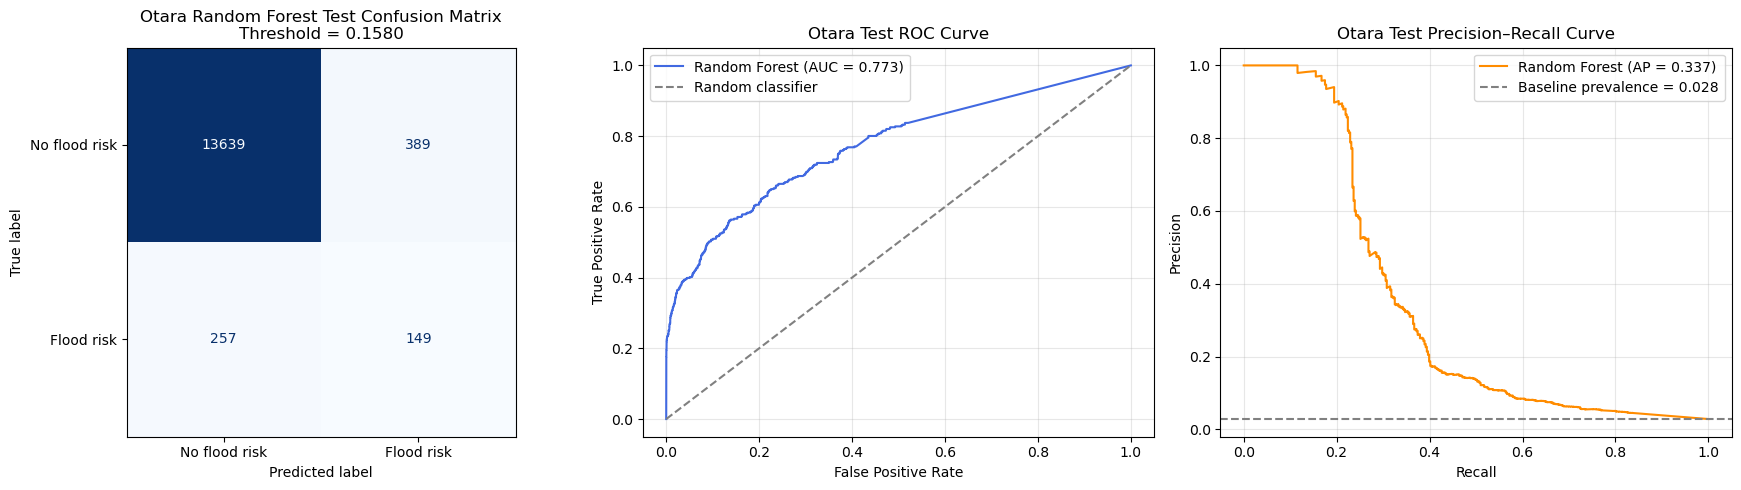

In [41]:
# Plot final test confusion matrix, ROC curve and PR curve

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

test_fpr, test_tpr, _ = roc_curve(
    y_test,
    test_probabilities
)

test_precision_curve, test_recall_curve, _ = (
    precision_recall_curve(
        y_test,
        test_probabilities
    )
)

test_baseline_prevalence = y_test.mean()

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["No flood risk", "Flood risk"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0]
)

axes[0].set_title(
    "Otara Random Forest Test Confusion Matrix\n"
    f"Threshold = {selected_threshold:.4f}"
)

# ROC curve
axes[1].plot(
    test_fpr,
    test_tpr,
    color="royalblue",
    label=f"Random Forest (AUC = {final_test_results['roc_auc']:.3f})"
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    label="Random classifier"
)

axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Otara Test ROC Curve")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Precision–recall curve
axes[2].plot(
    test_recall_curve,
    test_precision_curve,
    color="darkorange",
    label=f"Random Forest (AP = {final_test_results['pr_auc']:.3f})"
)

axes[2].axhline(
    test_baseline_prevalence,
    linestyle="--",
    color="grey",
    label=f"Baseline prevalence = {test_baseline_prevalence:.3f}"
)

axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_title("Otara Test Precision–Recall Curve")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
# Extract Random Forest feature importances

feature_importance_table = (
    pd.DataFrame({
        "feature": feature_columns,
        "importance": random_forest_model.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(
    feature_importance_table
    .head(15)
    .round(4)
)

,feature,importance
0,discharge_m3s,0.0707
1,water_level_m,0.0579
2,rainfall_sum_24h,0.0550
3,rainfall_sum_48h,0.0520
4,rainfall_sum_12h,0.0498
5,discharge_change_6h,0.0474
6,rainfall_sum_6h,0.0473
7,month_sin,0.0427
8,discharge_lag_1h,0.0425
9,month_cos,0.0400


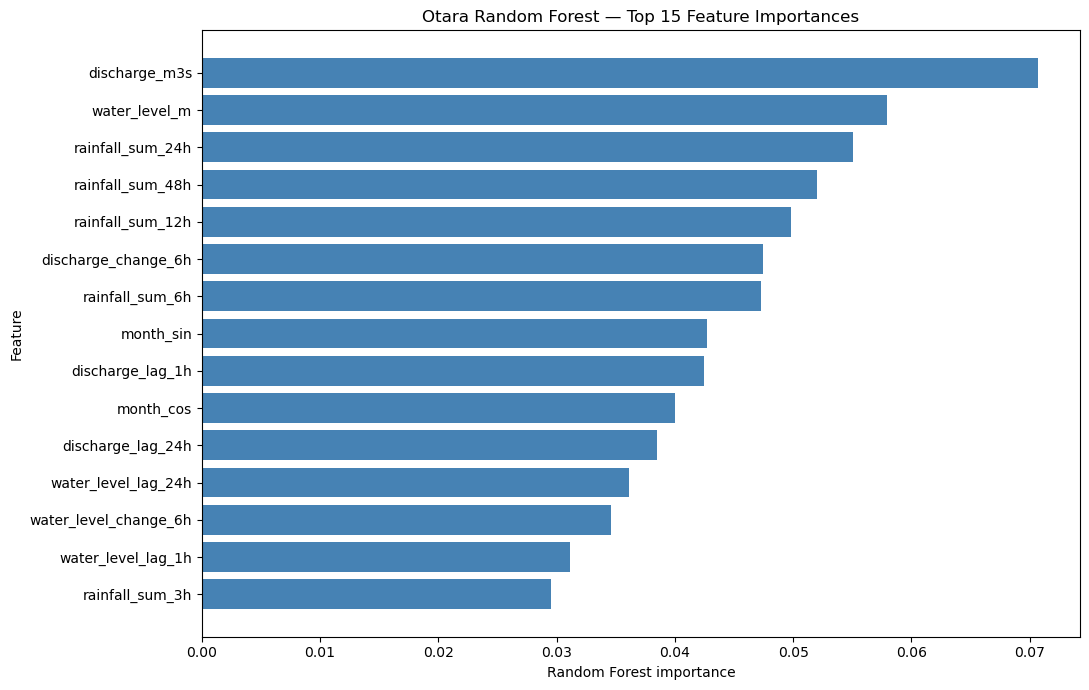

In [43]:
# Plot the 15 most influential Random Forest predictors

top_feature_importance = (
    feature_importance_table
    .head(15)
    .sort_values("importance", ascending=True)
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_feature_importance["feature"],
    top_feature_importance["importance"],
    color="steelblue"
)

plt.xlabel("Random Forest importance")
plt.ylabel("Feature")
plt.title(
    "Otara Random Forest — Top 15 Feature Importances"
)

plt.tight_layout()
plt.show()

## 12. Event-Level and Alert-Episode Evaluation

Hourly metrics can understate operational usefulness when a model detects part of a multi-hour flood-risk episode. Therefore, consecutive actual risk hours are grouped into events, and consecutive predicted risk hours are grouped into alert episodes. An actual event is considered detected when at least one hour within that event is predicted as flood risk. Alert-episode precision represents the proportion of alert episodes that overlap at least one actual risk hour.

In [44]:
# Combine final test observations, probabilities and predictions

test_diagnostics = pd.DataFrame({
    "timestamp": test_data["timestamp"].to_numpy(),
    "actual_risk": y_test.to_numpy(),
    "risk_probability": test_probabilities,
    "predicted_risk": test_predictions
})

test_diagnostics = (
    test_diagnostics
    .sort_values("timestamp")
    .reset_index(drop=True)
)

display(test_diagnostics.head())
print("Test-diagnostic rows:", len(test_diagnostics))

,timestamp,actual_risk,risk_probability,predicted_risk
0,2024-05-08 08:00:00,0,0.0,0
1,2024-05-08 09:00:00,0,0.0,0
2,2024-05-08 10:00:00,0,0.0,0
3,2024-05-08 11:00:00,0,0.0,0
4,2024-05-08 12:00:00,0,0.0,0


Test-diagnostic rows: 14434


In [45]:
# Assign an event ID to each consecutive actual flood-risk episode

actual_positive = (
    test_diagnostics["actual_risk"] == 1
)

continuous_from_previous = (
    test_diagnostics["timestamp"].diff()
    == pd.Timedelta(hours=1)
)

actual_event_start = (
    actual_positive
    & (
        ~actual_positive.shift(fill_value=False)
        | ~continuous_from_previous
    )
)

actual_event_numbers = actual_event_start.cumsum()

test_diagnostics["event_id"] = np.where(
    actual_positive,
    actual_event_numbers,
    np.nan
)

event_level_results = (
    test_diagnostics[
        test_diagnostics["event_id"].notna()
    ]
    .groupby("event_id")
    .agg(
        event_start=("timestamp", "min"),
        event_end=("timestamp", "max"),
        event_duration_hours=("actual_risk", "size"),
        detected_hours=("predicted_risk", "sum"),
        maximum_risk_score=("risk_probability", "max"),
        mean_risk_score=("risk_probability", "mean")
    )
)

event_level_results["event_detected"] = (
    event_level_results["detected_hours"] > 0
)

event_level_results["hourly_detection_percentage"] = (
    event_level_results["detected_hours"]
    / event_level_results["event_duration_hours"]
    * 100
)

total_risk_events = len(event_level_results)

detected_risk_events = int(
    event_level_results["event_detected"].sum()
)

missed_risk_events = (
    total_risk_events - detected_risk_events
)

event_level_recall = (
    detected_risk_events / total_risk_events
    if total_risk_events > 0
    else np.nan
)

print("EVENT-LEVEL TEST RESULTS")
print("Total flood-risk episodes:", total_risk_events)
print("Detected episodes:", detected_risk_events)
print("Completely missed episodes:", missed_risk_events)
print("Event-level recall:", round(event_level_recall, 3))

display(
    event_level_results
    .sort_values(
        "event_duration_hours",
        ascending=False
    )
    .round(3)
)

EVENT-LEVEL TEST RESULTS
Total flood-risk episodes: 14
Detected episodes: 14
Completely missed episodes: 0
Event-level recall: 1.0


,event_start,event_end,event_duration_hours,detected_hours,maximum_risk_score,mean_risk_score,event_detected,hourly_detection_percentage
event_id,,,,,,,,
11.0,2025-07-28 17:00:00,2025-07-30 04:00:00,36,17,0.997,0.398,True,47.222
10.0,2025-07-10 16:00:00,2025-07-12 00:00:00,33,18,0.997,0.363,True,54.545
6.0,2025-06-03 21:00:00,2025-06-05 03:00:00,31,10,1.000,0.271,True,32.258
9.0,2025-07-02 17:00:00,2025-07-03 23:00:00,31,18,0.993,0.347,True,58.065
14.0,2025-11-17 21:00:00,2025-11-19 02:00:00,30,9,0.986,0.241,True,30.000
5.0,2024-10-02 03:00:00,2024-10-03 07:00:00,29,10,0.976,0.210,True,34.483
7.0,2025-06-09 22:00:00,2025-06-11 02:00:00,29,7,0.996,0.222,True,24.138
8.0,2025-06-26 12:00:00,2025-06-27 16:00:00,29,9,0.996,0.270,True,31.034
1.0,2024-05-20 00:00:00,2024-05-21 03:00:00,28,8,0.959,0.174,True,28.571


In [46]:
# Assign an alert ID to each consecutive predicted-risk episode

predicted_positive = (
    test_diagnostics["predicted_risk"] == 1
)

predicted_alert_start = (
    predicted_positive
    & (
        ~predicted_positive.shift(fill_value=False)
        | ~continuous_from_previous
    )
)

predicted_alert_numbers = predicted_alert_start.cumsum()

test_diagnostics["alert_id"] = np.where(
    predicted_positive,
    predicted_alert_numbers,
    np.nan
)

alert_episode_results = (
    test_diagnostics[
        test_diagnostics["alert_id"].notna()
    ]
    .groupby("alert_id")
    .agg(
        alert_start=("timestamp", "min"),
        alert_end=("timestamp", "max"),
        alert_duration_hours=("predicted_risk", "size"),
        actual_risk_hours=("actual_risk", "sum"),
        maximum_risk_score=("risk_probability", "max"),
        mean_risk_score=("risk_probability", "mean")
    )
)

alert_episode_results["associated_with_risk"] = (
    alert_episode_results["actual_risk_hours"] > 0
)

total_alert_episodes = len(alert_episode_results)

risk_associated_alerts = int(
    alert_episode_results["associated_with_risk"].sum()
)

false_alert_episodes = (
    total_alert_episodes - risk_associated_alerts
)

alert_episode_precision = (
    risk_associated_alerts / total_alert_episodes
    if total_alert_episodes > 0
    else np.nan
)

print("ALERT-EPISODE TEST RESULTS")
print("Total alert episodes:", total_alert_episodes)
print(
    "Alert episodes overlapping a risk period:",
    risk_associated_alerts
)
print(
    "Alert episodes with no risk-period overlap:",
    false_alert_episodes
)
print(
    "Alert-episode precision:",
    round(alert_episode_precision, 3)
)

ALERT-EPISODE TEST RESULTS
Total alert episodes: 140
Alert episodes overlapping a risk period: 18
Alert episodes with no risk-period overlap: 122
Alert-episode precision: 0.129


In [47]:
# Compare durations of true and false alert episodes

alert_duration_summary = (
    alert_episode_results
    .groupby("associated_with_risk")["alert_duration_hours"]
    .agg(["count", "mean", "median", "max"])
)

display(
    alert_duration_summary.round(3)
)

,count,mean,median,max
associated_with_risk,,,,
False,122,2.844,2.0,14
True,18,10.611,10.5,20


In [48]:
# Inspect the longest alert episodes that did not overlap actual risk

longest_false_alerts = (
    alert_episode_results[
        ~alert_episode_results["associated_with_risk"]
    ]
    .sort_values(
        "alert_duration_hours",
        ascending=False
    )
    .head(15)
)

print("Longest false-alert episodes:")

display(
    longest_false_alerts.round(3)
)

Longest false-alert episodes:


,alert_start,alert_end,alert_duration_hours,actual_risk_hours,maximum_risk_score,mean_risk_score,associated_with_risk
alert_id,,,,,,,
13.0,2024-06-28 05:00:00,2024-06-28 18:00:00,14,0,0.599,0.419,False
66.0,2025-04-04 03:00:00,2025-04-04 13:00:00,11,0,0.642,0.432,False
35.0,2024-09-20 10:00:00,2024-09-20 19:00:00,10,0,0.750,0.419,False
8.0,2024-06-13 23:00:00,2024-06-14 07:00:00,9,0,0.461,0.333,False
73.0,2025-05-09 14:00:00,2025-05-09 22:00:00,9,0,0.620,0.318,False
124.0,2025-10-14 05:00:00,2025-10-14 13:00:00,9,0,0.682,0.471,False
25.0,2024-08-18 03:00:00,2024-08-18 11:00:00,9,0,0.294,0.230,False
24.0,2024-08-17 15:00:00,2024-08-17 23:00:00,9,0,0.406,0.345,False
19.0,2024-07-20 02:00:00,2024-07-20 10:00:00,9,0,0.499,0.359,False


## 13. Otara Modelling Conclusion

The Random Forest was selected over XGBoost using validation data because it achieved higher F2, recall, ROC-AUC and PR-AUC. When evaluated on the untouched test period, the selected Random Forest achieved:

- ROC-AUC: 0.7732
- PR-AUC: 0.3374, compared with a positive-class prevalence of 0.0281
- Precision: 0.2770
- Recall: 0.3670
- F1 score: 0.3157
- F2 score: 0.3446

Hourly performance was moderate: the model detected 149 of 406 flood-risk hours and generated 389 false-positive hours. However, event-level analysis showed that all 14 flood-risk episodes received at least one alert, resulting in event-level recall of 1.000.

This event-level result should be interpreted cautiously. Detection of at least one hour does not mean the complete event was predicted accurately; individual-event hourly coverage remained partial. The model also generated 140 separate alert episodes, of which only 18 overlapped actual risk periods, producing alert-episode precision of 0.129.

The Random Forest therefore demonstrates useful predictive signal and strong event-screening capability, but its false-alert frequency and incomplete hourly coverage limit its suitability as a standalone operational warning system. Further improvements may include temporal alert smoothing, event-based threshold selection, additional upstream or weather predictors, probability calibration and comparison with sequence models such as LSTM.

In [49]:
# Save the final Otara datasets and model results

output_directory = Path("otara_outputs")
output_directory.mkdir(exist_ok=True)

otara_base.to_csv(
    output_directory / "otara_base.csv",
    index=False
)

otara_preprocessed.to_csv(
    output_directory / "otara_preprocessed.csv",
    index=False
)

modelling_dataset.to_csv(
    output_directory / "otara_modelling_dataset.csv",
    index=False
)

validation_comparison.to_csv(
    output_directory / "otara_model_validation_comparison.csv"
)

feature_importance_table.to_csv(
    output_directory / "otara_random_forest_feature_importance.csv",
    index=False
)

test_diagnostics.to_csv(
    output_directory / "otara_test_predictions.csv",
    index=False
)

event_level_results.to_csv(
    output_directory / "otara_event_level_results.csv"
)

alert_episode_results.to_csv(
    output_directory / "otara_alert_episode_results.csv"
)

print("Saved Otara outputs:")

for saved_file in sorted(output_directory.glob("*.csv")):
    print("-", saved_file)

Saved Otara outputs:
- otara_outputs\otara_alert_episode_results.csv
- otara_outputs\otara_base.csv
- otara_outputs\otara_event_level_results.csv
- otara_outputs\otara_model_validation_comparison.csv
- otara_outputs\otara_modelling_dataset.csv
- otara_outputs\otara_preprocessed.csv
- otara_outputs\otara_random_forest_feature_importance.csv
- otara_outputs\otara_test_predictions.csv


In [50]:
# PREPARE OTARA DATA FOR GAUSSIAN NAIVE BAYES

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB

required_variables = [
    "X_train",
    "y_train",
    "X_validation",
    "y_validation",
    "X_test",
    "y_test"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing required variables: {missing_variables}"
    )

assert X_train.shape[1] == X_validation.shape[1]
assert X_train.shape[1] == X_test.shape[1]

assert not X_train.isna().any().any()
assert not X_validation.isna().any().any()
assert not X_test.isna().any().any()

assert set(y_train.unique()).issubset({0, 1})
assert set(y_validation.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

print(
    f"Training: {X_train.shape[0]} rows, "
    f"{X_train.shape[1]} features, "
    f"{int(y_train.sum())} high-risk rows"
)

print(
    f"Validation: {X_validation.shape[0]} rows, "
    f"{X_validation.shape[1]} features, "
    f"{int(y_validation.sum())} high-risk rows"
)

print(
    f"Test: {X_test.shape[0]} rows, "
    f"{X_test.shape[1]} features, "
    f"{int(y_test.sum())} high-risk rows"
)

Training: 66396 rows, 36 features, 1403 high-risk rows
Validation: 14373 rows, 36 features, 477 high-risk rows
Test: 14434 rows, 36 features, 406 high-risk rows


In [51]:
# TUNE OTARA GAUSSIAN NAIVE BAYES

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

var_smoothing_values = np.logspace(
    -12,
    8,
    41
)

tuning_records = []

for var_smoothing in var_smoothing_values:
    candidate_model = Pipeline([
        ("scaler", StandardScaler()),
        (
            "naive_bayes",
            GaussianNB(
                var_smoothing=var_smoothing
            )
        )
    ])

    candidate_model.fit(
        X_train,
        y_train
    )

    candidate_probability = (
        candidate_model
        .predict_proba(X_validation)[:, 1]
    )

    precision_values, recall_values, threshold_values = (
        precision_recall_curve(
            y_validation,
            candidate_probability
        )
    )

    precision_for_thresholds = precision_values[:-1]
    recall_for_thresholds = recall_values[:-1]

    f2_values = (
        5
        * precision_for_thresholds
        * recall_for_thresholds
        / (
            4 * precision_for_thresholds
            + recall_for_thresholds
            + 1e-12
        )
    )

    best_index = int(
        np.argmax(f2_values)
    )

    tuning_records.append({
        "var_smoothing": var_smoothing,
        "selected_threshold":
            threshold_values[best_index],
        "validation_precision":
            precision_for_thresholds[best_index],
        "validation_recall":
            recall_for_thresholds[best_index],
        "validation_f2":
            f2_values[best_index],
        "validation_roc_auc":
            roc_auc_score(
                y_validation,
                candidate_probability
            ),
        "validation_pr_auc":
            average_precision_score(
                y_validation,
                candidate_probability
            )
    })

otara_naive_bayes_tuning_results = pd.DataFrame(
    tuning_records
)

best_naive_bayes_result = (
    otara_naive_bayes_tuning_results
    .sort_values(
        [
            "validation_f2",
            "validation_pr_auc",
            "validation_roc_auc"
        ],
        ascending=False
    )
    .iloc[0]
)

selected_var_smoothing = float(
    best_naive_bayes_result["var_smoothing"]
)

selected_probability_threshold = float(
    best_naive_bayes_result["selected_threshold"]
)

print(
    "Selected var_smoothing:",
    f"{selected_var_smoothing:.6e}"
)

print(
    "Selected probability threshold:",
    f"{selected_probability_threshold:.6e}"
)

print(
    "Maximum validation F2:",
    round(
        best_naive_bayes_result["validation_f2"],
        4
    )
)

print("\nTop validation results:")

display(
    otara_naive_bayes_tuning_results
    .sort_values(
        [
            "validation_f2",
            "validation_pr_auc",
            "validation_roc_auc"
        ],
        ascending=False
    )
    .head(10)
    .round(4)
)

Selected var_smoothing: 3.162278e+03
Selected probability threshold: 1.976036e-02
Maximum validation F2: 0.4335

Top validation results:


,var_smoothing,selected_threshold,validation_precision,validation_recall,validation_f2,validation_roc_auc,validation_pr_auc
31,3.162278e+03,0.0198,0.3880,0.4465,0.4335,0.8428,0.4292
32,1.000000e+04,0.0207,0.3873,0.4465,0.4333,0.8428,0.4294
36,1.000000e+06,0.0211,0.3866,0.4465,0.4331,0.8428,0.4294
37,3.162278e+06,0.0211,0.3866,0.4465,0.4331,0.8428,0.4294
38,1.000000e+07,0.0211,0.3866,0.4465,0.4331,0.8428,0.4294
39,3.162278e+07,0.0211,0.3866,0.4465,0.4331,0.8428,0.4294
40,1.000000e+08,0.0211,0.3866,0.4465,0.4331,0.8428,0.4294
34,1.000000e+05,0.0211,0.3866,0.4465,0.4331,0.8428,0.4294
35,3.162278e+05,0.0211,0.3866,0.4465,0.4331,0.8428,0.4294
33,3.162278e+04,0.0210,0.3866,0.4465,0.4331,0.8428,0.4294


In [52]:
# FIT FINAL OTARA GAUSSIAN NAIVE BAYES MODEL

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

otara_naive_bayes_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "naive_bayes",
        GaussianNB(
            var_smoothing=selected_var_smoothing
        )
    )
])

otara_naive_bayes_model.fit(
    X_train,
    y_train
)

training_probability_nb = (
    otara_naive_bayes_model
    .predict_proba(X_train)[:, 1]
)

validation_probability_nb = (
    otara_naive_bayes_model
    .predict_proba(X_validation)[:, 1]
)

validation_prediction_nb = (
    validation_probability_nb
    >= selected_probability_threshold
).astype(int)

validation_tn, validation_fp, validation_fn, validation_tp = (
    confusion_matrix(
        y_validation,
        validation_prediction_nb,
        labels=[0, 1]
    ).ravel()
)

otara_naive_bayes_validation_results = pd.DataFrame([{
    "var_smoothing":
        selected_var_smoothing,
    "selected_threshold":
        selected_probability_threshold,
    "rows":
        len(y_validation),
    "actual_high_risk":
        int(y_validation.sum()),
    "predicted_high_risk":
        int(validation_prediction_nb.sum()),
    "accuracy":
        accuracy_score(
            y_validation,
            validation_prediction_nb
        ),
    "balanced_accuracy":
        balanced_accuracy_score(
            y_validation,
            validation_prediction_nb
        ),
    "precision":
        precision_score(
            y_validation,
            validation_prediction_nb,
            zero_division=0
        ),
    "recall":
        recall_score(
            y_validation,
            validation_prediction_nb,
            zero_division=0
        ),
    "f1_score":
        f1_score(
            y_validation,
            validation_prediction_nb,
            zero_division=0
        ),
    "f2_score":
        fbeta_score(
            y_validation,
            validation_prediction_nb,
            beta=2,
            zero_division=0
        ),
    "roc_auc":
        roc_auc_score(
            y_validation,
            validation_probability_nb
        ),
    "pr_auc":
        average_precision_score(
            y_validation,
            validation_probability_nb
        ),
    "true_negatives":
        validation_tn,
    "false_positives":
        validation_fp,
    "false_negatives":
        validation_fn,
    "true_positives":
        validation_tp
}])

print("Gaussian Naive Bayes fitted successfully.")

print(
    "Selected var_smoothing:",
    f"{selected_var_smoothing:.6e}"
)

print(
    "Frozen validation-selected threshold:",
    f"{selected_probability_threshold:.6e}"
)

display(
    otara_naive_bayes_validation_results
    .round(4)
)

Gaussian Naive Bayes fitted successfully.
Selected var_smoothing: 3.162278e+03
Frozen validation-selected threshold: 1.976036e-02


,var_smoothing,selected_threshold,rows,actual_high_risk,predicted_high_risk,accuracy,balanced_accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc,true_negatives,false_positives,false_negatives,true_positives
0,3162.2777,0.0198,14373,477,549,0.9583,0.7112,0.388,0.4465,0.4152,0.4335,0.8428,0.4292,13560,336,264,213


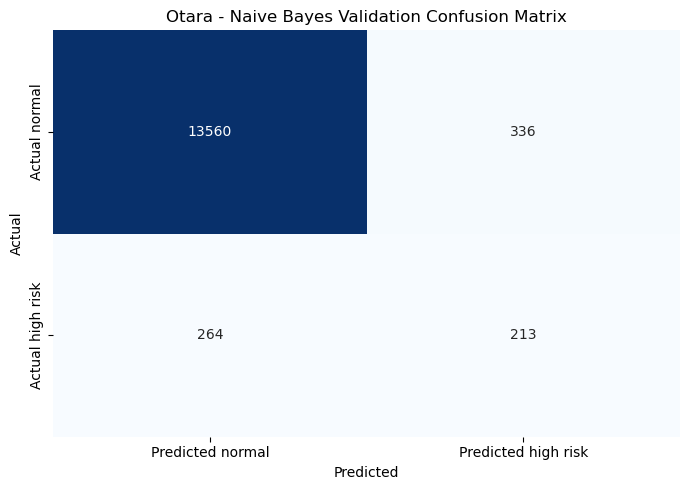

Validation classification report:

              precision    recall  f1-score   support

      Normal     0.9809    0.9758    0.9784     13896
   High risk     0.3880    0.4465    0.4152       477

    accuracy                         0.9583     14373
   macro avg     0.6844    0.7112    0.6968     14373
weighted avg     0.9612    0.9583    0.9597     14373



In [54]:
# OTARA NAIVE BAYES VALIDATION CONFUSION MATRIX

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report

otara_naive_bayes_validation_confusion = (
    confusion_matrix(
        y_validation,
        validation_prediction_nb,
        labels=[0, 1]
    )
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    otara_naive_bayes_validation_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=[
        "Predicted normal",
        "Predicted high risk"
    ],
    yticklabels=[
        "Actual normal",
        "Actual high risk"
    ]
)

plt.title(
    "Otara - Naive Bayes Validation Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print("Validation classification report:\n")

print(
    classification_report(
        y_validation,
        validation_prediction_nb,
        target_names=[
            "Normal",
            "High risk"
        ],
        digits=4,
        zero_division=0
    )
)

In [56]:
# EVALUATE OTARA NAIVE BAYES ON THE UNTOUCHED TEST SET

test_probability_nb = (
    otara_naive_bayes_model
    .predict_proba(X_test)[:, 1]
)

test_prediction_nb = (
    test_probability_nb
    >= selected_probability_threshold
).astype(int)

test_tn, test_fp, test_fn, test_tp = (
    confusion_matrix(
        y_test,
        test_prediction_nb,
        labels=[0, 1]
    ).ravel()
)

otara_naive_bayes_test_results = pd.DataFrame([{
    "model":
        "Gaussian Naive Bayes",
    "var_smoothing":
        selected_var_smoothing,
    "selected_threshold":
        selected_probability_threshold,
    "rows":
        len(y_test),
    "actual_high_risk":
        int(y_test.sum()),
    "predicted_high_risk":
        int(test_prediction_nb.sum()),
    "accuracy":
        accuracy_score(
            y_test,
            test_prediction_nb
        ),
    "balanced_accuracy":
        balanced_accuracy_score(
            y_test,
            test_prediction_nb
        ),
    "precision":
        precision_score(
            y_test,
            test_prediction_nb,
            zero_division=0
        ),
    "recall":
        recall_score(
            y_test,
            test_prediction_nb,
            zero_division=0
        ),
    "f1_score":
        f1_score(
            y_test,
            test_prediction_nb,
            zero_division=0
        ),
    "f2_score":
        fbeta_score(
            y_test,
            test_prediction_nb,
            beta=2,
            zero_division=0
        ),
    "roc_auc":
        roc_auc_score(
            y_test,
            test_probability_nb
        ),
    "pr_auc":
        average_precision_score(
            y_test,
            test_probability_nb
        ),
    "true_negatives":
        test_tn,
    "false_positives":
        test_fp,
    "false_negatives":
        test_fn,
    "true_positives":
        test_tp
}])

otara_naive_bayes_test_predictions = pd.DataFrame({
    "timestamp":
        pd.to_datetime(test_data["timestamp"]),
    "observed_flood_risk_next_24h":
        np.asarray(y_test),
    "naive_bayes_score":
        test_probability_nb,
    "predicted_flood_risk_next_24h":
        test_prediction_nb,
    "rainfall_mm":
        np.asarray(test_data["rainfall_mm"]),
    "discharge_m3s":
        np.asarray(test_data["discharge_m3s"]),
    "water_level_m":
        np.asarray(test_data["water_level_m"])
})

print("OTARA GAUSSIAN NAIVE BAYES - FINAL UNTOUCHED-TEST RESULTS")

display(
    otara_naive_bayes_test_results
    .round(4)
)

print("Test prediction rows:", len(
    otara_naive_bayes_test_predictions
))

print(
    "Missing prediction values:",
    int(
        otara_naive_bayes_test_predictions
        .isna()
        .sum()
        .sum()
    )
)

display(
    otara_naive_bayes_test_predictions
    .head()
    .round(4)
)

OTARA GAUSSIAN NAIVE BAYES - FINAL UNTOUCHED-TEST RESULTS


,model,var_smoothing,selected_threshold,rows,actual_high_risk,predicted_high_risk,accuracy,balanced_accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc,true_negatives,false_positives,false_negatives,true_positives
0,Gaussian Naive Bayes,3162.2777,0.0198,14434,406,452,0.9565,0.6296,0.2544,0.2833,0.2681,0.277,0.7626,0.2928,13691,337,291,115


Test prediction rows: 14434
Missing prediction values: 0


,timestamp,observed_flood_risk_next_24h,naive_bayes_score,predicted_flood_risk_next_24h,rainfall_mm,discharge_m3s,water_level_m
80769,2024-05-08 08:00:00,0,0.0191,0,0.0,0.056,0.445
80770,2024-05-08 09:00:00,0,0.0191,0,0.0,0.056,0.445
80771,2024-05-08 10:00:00,0,0.0191,0,0.0,0.056,0.445
80772,2024-05-08 11:00:00,0,0.0191,0,0.0,0.056,0.445
80773,2024-05-08 12:00:00,0,0.0191,0,0.0,0.056,0.445


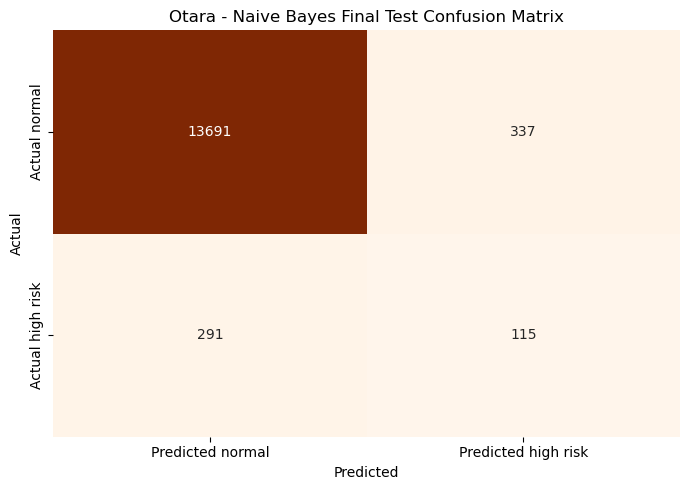

Final test classification report:

              precision    recall  f1-score   support

      Normal     0.9792    0.9760    0.9776     14028
   High risk     0.2544    0.2833    0.2681       406

    accuracy                         0.9565     14434
   macro avg     0.6168    0.6296    0.6228     14434
weighted avg     0.9588    0.9565    0.9576     14434



In [57]:
# OTARA NAIVE BAYES TEST CONFUSION MATRIX

from sklearn.metrics import classification_report

otara_naive_bayes_test_confusion = (
    confusion_matrix(
        y_test,
        test_prediction_nb,
        labels=[0, 1]
    )
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    otara_naive_bayes_test_confusion,
    annot=True,
    fmt="d",
    cmap="Oranges",
    cbar=False,
    xticklabels=[
        "Predicted normal",
        "Predicted high risk"
    ],
    yticklabels=[
        "Actual normal",
        "Actual high risk"
    ]
)

plt.title(
    "Otara - Naive Bayes Final Test Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print("Final test classification report:\n")

print(
    classification_report(
        y_test,
        test_prediction_nb,
        target_names=[
            "Normal",
            "High risk"
        ],
        digits=4,
        zero_division=0
    )
)

In [58]:
# OTARA NAIVE BAYES EVENT-LEVEL TEST RESULTS

def assign_episode_ids(timestamps, binary_values):
    timestamps = pd.Series(
        pd.to_datetime(timestamps)
    ).reset_index(drop=True)

    binary_values = pd.Series(
        binary_values
    ).astype(int).reset_index(drop=True)

    previous_positive = (
        binary_values.shift(fill_value=0) == 1
    )

    consecutive_hour = (
        timestamps.diff()
        == pd.Timedelta(hours=1)
    )

    episode_start = (
        (binary_values == 1)
        & (
            (~previous_positive)
            | (~consecutive_hour)
        )
    )

    episode_ids = episode_start.cumsum()

    return episode_ids.where(
        binary_values == 1,
        0
    )


event_evaluation_nb = pd.DataFrame({
    "timestamp":
        pd.to_datetime(test_data["timestamp"])
        .reset_index(drop=True),
    "actual_risk":
        np.asarray(y_test),
    "predicted_risk":
        test_prediction_nb,
    "naive_bayes_score":
        test_probability_nb,
    "water_level_m":
        np.asarray(test_data["water_level_m"])
})

event_evaluation_nb["event_id"] = assign_episode_ids(
    event_evaluation_nb["timestamp"],
    event_evaluation_nb["actual_risk"]
)

event_rows_nb = event_evaluation_nb[
    event_evaluation_nb["event_id"] > 0
].copy()

otara_naive_bayes_event_results = (
    event_rows_nb
    .groupby("event_id")
    .agg(
        event_start=("timestamp", "min"),
        event_end=("timestamp", "max"),
        event_hours=("actual_risk", "size"),
        detected_hours=("predicted_risk", "sum"),
        maximum_naive_bayes_score=(
            "naive_bayes_score",
            "max"
        ),
        mean_naive_bayes_score=(
            "naive_bayes_score",
            "mean"
        ),
        maximum_water_level_m=(
            "water_level_m",
            "max"
        )
    )
    .reset_index()
)

otara_naive_bayes_event_results["event_detected"] = (
    otara_naive_bayes_event_results[
        "detected_hours"
    ] > 0
)

otara_naive_bayes_event_results[
    "hourly_detection_percentage"
] = (
    otara_naive_bayes_event_results[
        "detected_hours"
    ]
    / otara_naive_bayes_event_results[
        "event_hours"
    ]
    * 100
)

total_physical_events_nb = len(
    otara_naive_bayes_event_results
)

detected_physical_events_nb = int(
    otara_naive_bayes_event_results[
        "event_detected"
    ].sum()
)

event_level_recall_nb = (
    detected_physical_events_nb
    / total_physical_events_nb
    if total_physical_events_nb > 0
    else 0
)

otara_naive_bayes_event_summary = pd.DataFrame([{
    "physical_high_risk_events":
        total_physical_events_nb,
    "events_detected":
        detected_physical_events_nb,
    "event_level_recall":
        event_level_recall_nb
}])

print(
    "Physical high-risk events:",
    total_physical_events_nb
)

print(
    "Events detected:",
    detected_physical_events_nb
)

print(
    "Event-level recall:",
    round(event_level_recall_nb, 4)
)

display(
    otara_naive_bayes_event_results
    .round(4)
)

Physical high-risk events: 14
Events detected: 14
Event-level recall: 1.0


,event_id,event_start,event_end,event_hours,detected_hours,maximum_naive_bayes_score,mean_naive_bayes_score,maximum_water_level_m,event_detected,hourly_detection_percentage
0,1,2024-05-20 00:00:00,2024-05-21 03:00:00,28,6,0.0216,0.0196,1.430,True,21.4286
1,2,2024-06-16 02:00:00,2024-06-17 03:00:00,26,5,0.0206,0.0195,1.320,True,19.2308
2,3,2024-06-22 07:00:00,2024-06-23 07:00:00,25,6,0.0208,0.0195,1.258,True,24.0000
3,4,2024-08-31 04:00:00,2024-09-01 07:00:00,28,6,0.0224,0.0198,1.724,True,21.4286
4,5,2024-10-02 03:00:00,2024-10-03 07:00:00,29,10,0.0211,0.0196,1.380,True,34.4828
5,6,2025-06-03 21:00:00,2025-06-05 03:00:00,31,8,0.0238,0.0201,2.142,True,25.8065
6,7,2025-06-09 22:00:00,2025-06-11 02:00:00,29,7,0.0217,0.0198,1.510,True,24.1379
7,8,2025-06-26 12:00:00,2025-06-27 16:00:00,29,8,0.0222,0.0198,1.707,True,27.5862
8,9,2025-07-02 17:00:00,2025-07-03 23:00:00,31,9,0.0211,0.0197,1.507,True,29.0323
9,10,2025-07-10 16:00:00,2025-07-12 00:00:00,33,13,0.0228,0.0202,2.005,True,39.3939


In [59]:
# OTARA NAIVE BAYES ALERT-EPISODE RESULTS

alert_evaluation_nb = event_evaluation_nb.copy()

alert_evaluation_nb["alert_id"] = assign_episode_ids(
    alert_evaluation_nb["timestamp"],
    alert_evaluation_nb["predicted_risk"]
)

alert_rows_nb = alert_evaluation_nb[
    alert_evaluation_nb["alert_id"] > 0
].copy()

otara_naive_bayes_alert_results = (
    alert_rows_nb
    .groupby("alert_id")
    .agg(
        alert_start=("timestamp", "min"),
        alert_end=("timestamp", "max"),
        alert_hours=("predicted_risk", "size"),
        actual_risk_hours=("actual_risk", "sum"),
        maximum_naive_bayes_score=(
            "naive_bayes_score",
            "max"
        ),
        mean_naive_bayes_score=(
            "naive_bayes_score",
            "mean"
        )
    )
    .reset_index()
)

otara_naive_bayes_alert_results[
    "associated_with_risk"
] = (
    otara_naive_bayes_alert_results[
        "actual_risk_hours"
    ] > 0
)

total_alert_episodes_nb = len(
    otara_naive_bayes_alert_results
)

risk_associated_alert_episodes_nb = int(
    otara_naive_bayes_alert_results[
        "associated_with_risk"
    ].sum()
)

false_alert_episodes_nb = (
    total_alert_episodes_nb
    - risk_associated_alert_episodes_nb
)

alert_episode_precision_nb = (
    risk_associated_alert_episodes_nb
    / total_alert_episodes_nb
    if total_alert_episodes_nb > 0
    else 0
)

print(
    "Total predicted alert episodes:",
    total_alert_episodes_nb
)

print(
    "Risk-associated alert episodes:",
    risk_associated_alert_episodes_nb
)

print(
    "False alert episodes:",
    false_alert_episodes_nb
)

print(
    "Alert-episode precision:",
    round(alert_episode_precision_nb, 4)
)

display(
    otara_naive_bayes_alert_results
    .head(20)
    .round(4)
)

Total predicted alert episodes: 50
Risk-associated alert episodes: 16
False alert episodes: 34
Alert-episode precision: 0.32


,alert_id,alert_start,alert_end,alert_hours,actual_risk_hours,maximum_naive_bayes_score,mean_naive_bayes_score,associated_with_risk
0,1,2024-05-15 07:00:00,2024-05-15 08:00:00,2,0,0.0199,0.0199,False
1,2,2024-05-20 22:00:00,2024-05-21 08:00:00,11,6,0.0216,0.0207,True
2,3,2024-05-21 12:00:00,2024-05-21 12:00:00,1,0,0.0198,0.0198,False
3,4,2024-06-10 01:00:00,2024-06-10 07:00:00,7,0,0.0200,0.0199,False
4,5,2024-06-14 02:00:00,2024-06-14 19:00:00,18,0,0.0207,0.0202,False
5,6,2024-06-14 22:00:00,2024-06-15 01:00:00,4,0,0.0198,0.0198,False
6,7,2024-06-16 23:00:00,2024-06-17 06:00:00,8,5,0.0206,0.0203,True
7,8,2024-06-23 02:00:00,2024-06-23 12:00:00,11,6,0.0208,0.0203,True
8,9,2024-07-20 05:00:00,2024-07-20 11:00:00,7,0,0.0201,0.0199,False
9,10,2024-07-30 16:00:00,2024-07-30 20:00:00,5,0,0.0199,0.0198,False


In [60]:
# OTARA NAIVE BAYES TRAINING AND TEST PERFORMANCE

training_prediction_nb = (
    training_probability_nb
    >= selected_probability_threshold
).astype(int)

otara_naive_bayes_train_test_comparison = pd.DataFrame({
    "Training": {
        "Accuracy":
            accuracy_score(
                y_train,
                training_prediction_nb
            ),
        "Balanced accuracy":
            balanced_accuracy_score(
                y_train,
                training_prediction_nb
            ),
        "Precision":
            precision_score(
                y_train,
                training_prediction_nb,
                zero_division=0
            ),
        "Recall":
            recall_score(
                y_train,
                training_prediction_nb,
                zero_division=0
            ),
        "F1":
            f1_score(
                y_train,
                training_prediction_nb,
                zero_division=0
            ),
        "F2":
            fbeta_score(
                y_train,
                training_prediction_nb,
                beta=2,
                zero_division=0
            ),
        "ROC-AUC":
            roc_auc_score(
                y_train,
                training_probability_nb
            ),
        "PR-AUC":
            average_precision_score(
                y_train,
                training_probability_nb
            )
    },

    "Test": {
        "Accuracy":
            accuracy_score(
                y_test,
                test_prediction_nb
            ),
        "Balanced accuracy":
            balanced_accuracy_score(
                y_test,
                test_prediction_nb
            ),
        "Precision":
            precision_score(
                y_test,
                test_prediction_nb,
                zero_division=0
            ),
        "Recall":
            recall_score(
                y_test,
                test_prediction_nb,
                zero_division=0
            ),
        "F1":
            f1_score(
                y_test,
                test_prediction_nb,
                zero_division=0
            ),
        "F2":
            fbeta_score(
                y_test,
                test_prediction_nb,
                beta=2,
                zero_division=0
            ),
        "ROC-AUC":
            roc_auc_score(
                y_test,
                test_probability_nb
            ),
        "PR-AUC":
            average_precision_score(
                y_test,
                test_probability_nb
            )
    }
})

print(
    "OTARA NAIVE BAYES TRAINING VERSUS TEST PERFORMANCE"
)

display(
    otara_naive_bayes_train_test_comparison
    .round(4)
)

OTARA NAIVE BAYES TRAINING VERSUS TEST PERFORMANCE


,Training,Test
Accuracy,0.9704,0.9565
Balanced accuracy,0.6878,0.6296
Precision,0.3309,0.2544
Recall,0.3927,0.2833
F1,0.3592,0.2681
F2,0.3786,0.2770
ROC-AUC,0.8323,0.7626
PR-AUC,0.3798,0.2928


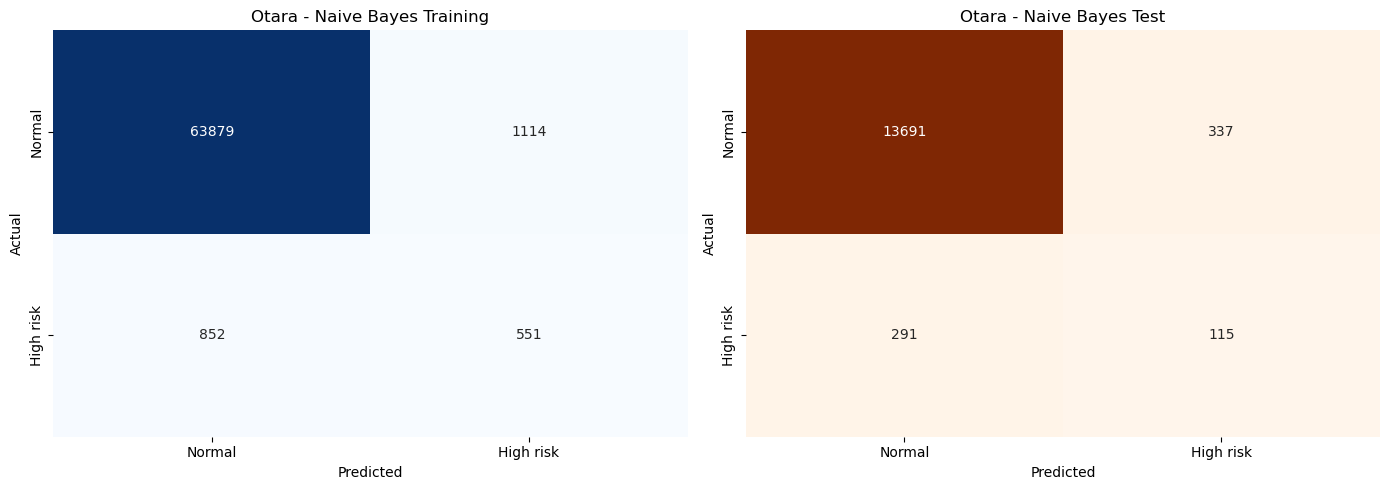

In [61]:
# OTARA NAIVE BAYES TRAINING AND TEST CONFUSION MATRICES

otara_naive_bayes_training_confusion = confusion_matrix(
    y_train,
    training_prediction_nb,
    labels=[0, 1]
)

otara_naive_bayes_test_confusion = confusion_matrix(
    y_test,
    test_prediction_nb,
    labels=[0, 1]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    otara_naive_bayes_training_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Normal", "High risk"],
    yticklabels=["Normal", "High risk"],
    ax=axes[0]
)

axes[0].set_title("Otara - Naive Bayes Training")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    otara_naive_bayes_test_confusion,
    annot=True,
    fmt="d",
    cmap="Oranges",
    cbar=False,
    xticklabels=["Normal", "High risk"],
    yticklabels=["Normal", "High risk"],
    ax=axes[1]
)

axes[1].set_title("Otara - Naive Bayes Test")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

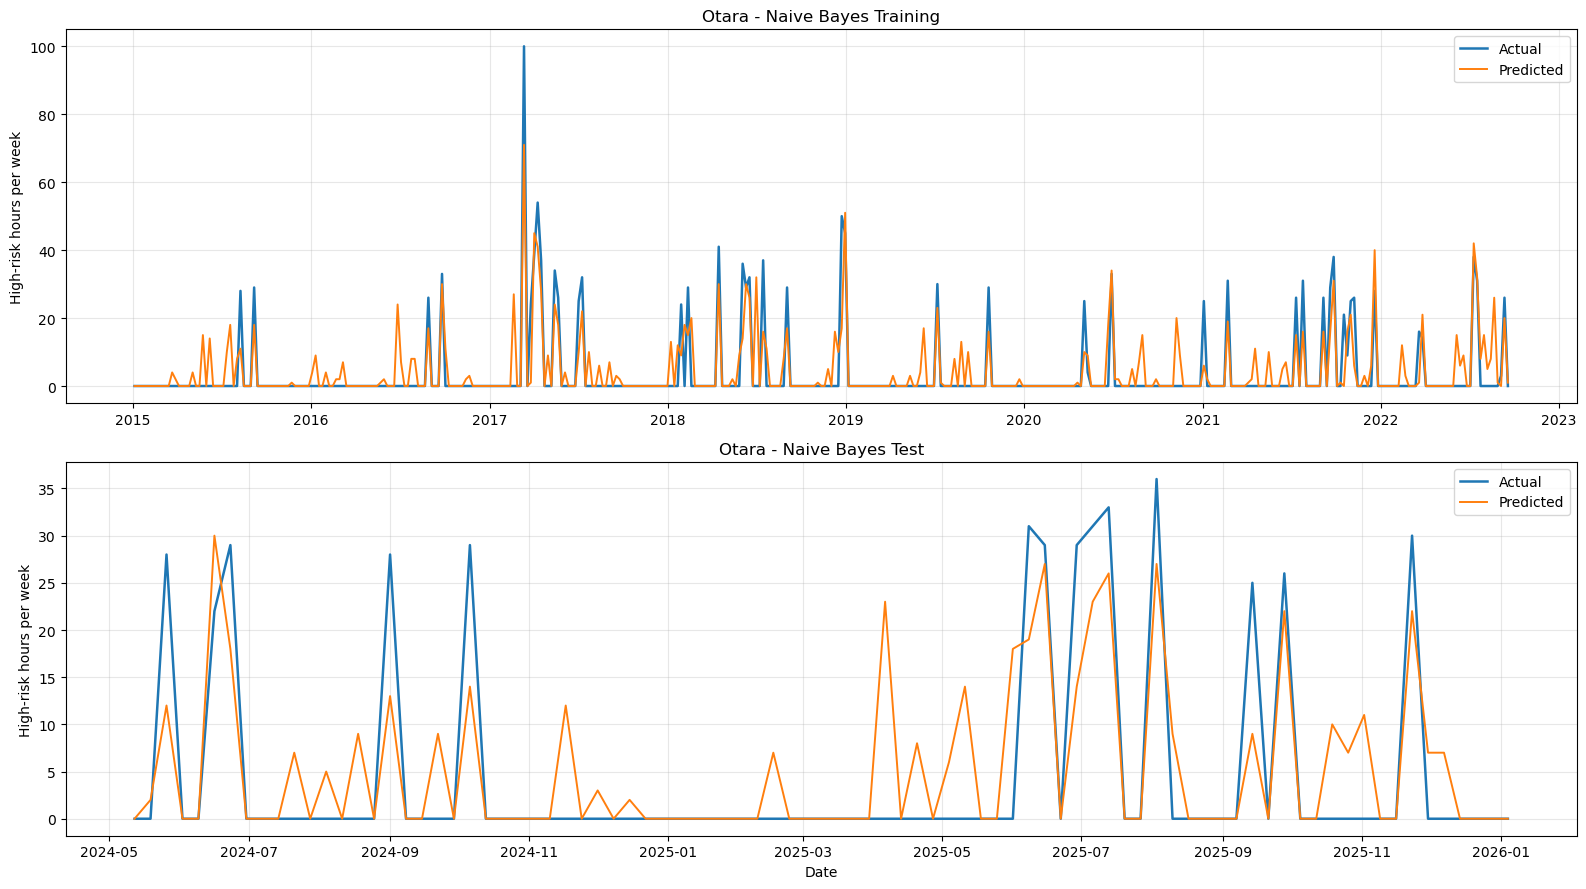

In [62]:
# OTARA NAIVE BAYES ACTUAL VERSUS PREDICTED WEEKLY HIGH-RISK HOURS

otara_nb_training_weekly = pd.DataFrame({
    "timestamp": pd.to_datetime(train_data["timestamp"]),
    "Actual": y_train.to_numpy(),
    "Predicted": training_prediction_nb
}).set_index("timestamp").resample("W").sum()

otara_nb_test_weekly = pd.DataFrame({
    "timestamp": pd.to_datetime(test_data["timestamp"]),
    "Actual": y_test.to_numpy(),
    "Predicted": test_prediction_nb
}).set_index("timestamp").resample("W").sum()

fig, axes = plt.subplots(2, 1, figsize=(16, 9))

axes[0].plot(
    otara_nb_training_weekly.index,
    otara_nb_training_weekly["Actual"],
    label="Actual",
    linewidth=1.8
)
axes[0].plot(
    otara_nb_training_weekly.index,
    otara_nb_training_weekly["Predicted"],
    label="Predicted",
    linewidth=1.4
)
axes[0].set_title("Otara - Naive Bayes Training")
axes[0].set_ylabel("High-risk hours per week")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    otara_nb_test_weekly.index,
    otara_nb_test_weekly["Actual"],
    label="Actual",
    linewidth=1.8
)
axes[1].plot(
    otara_nb_test_weekly.index,
    otara_nb_test_weekly["Predicted"],
    label="Predicted",
    linewidth=1.4
)
axes[1].set_title("Otara - Naive Bayes Test")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("High-risk hours per week")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [63]:
# OTARA XGBOOST FINAL UNTOUCHED-TEST EVALUATION

xgboost_selected_threshold = float(xgb_best_f2_option["threshold"])

xgboost_test_probability = xgboost_model.predict_proba(X_test)[:, 1]

xgboost_test_prediction = (
    xgboost_test_probability >= xgboost_selected_threshold
).astype(int)

xgb_test_tn, xgb_test_fp, xgb_test_fn, xgb_test_tp = confusion_matrix(
    y_test,
    xgboost_test_prediction,
    labels=[0, 1]
).ravel()

otara_xgboost_test_results = pd.DataFrame({
    "model": ["XGBoost"],
    "selected_threshold": [xgboost_selected_threshold],
    "rows": [len(y_test)],
    "actual_high_risk": [int(y_test.sum())],
    "predicted_high_risk": [int(xgboost_test_prediction.sum())],
    "accuracy": [accuracy_score(y_test, xgboost_test_prediction)],
    "balanced_accuracy": [
        balanced_accuracy_score(y_test, xgboost_test_prediction)
    ],
    "precision": [
        precision_score(
            y_test,
            xgboost_test_prediction,
            zero_division=0
        )
    ],
    "recall": [
        recall_score(
            y_test,
            xgboost_test_prediction,
            zero_division=0
        )
    ],
    "f1_score": [
        f1_score(
            y_test,
            xgboost_test_prediction,
            zero_division=0
        )
    ],
    "f2_score": [
        fbeta_score(
            y_test,
            xgboost_test_prediction,
            beta=2,
            zero_division=0
        )
    ],
    "roc_auc": [roc_auc_score(y_test, xgboost_test_probability)],
    "pr_auc": [average_precision_score(y_test, xgboost_test_probability)],
    "true_negatives": [xgb_test_tn],
    "false_positives": [xgb_test_fp],
    "false_negatives": [xgb_test_fn],
    "true_positives": [xgb_test_tp]
})

print("OTARA XGBOOST - FINAL UNTOUCHED-TEST RESULTS")
display(otara_xgboost_test_results.round(4))

print("\nFinal test confusion matrix:")
display(pd.DataFrame(
    [[xgb_test_tn, xgb_test_fp],
     [xgb_test_fn, xgb_test_tp]],
    index=["Actual normal", "Actual high risk"],
    columns=["Predicted normal", "Predicted high risk"]
))

print("\nFinal test classification report:")
print(classification_report(
    y_test,
    xgboost_test_prediction,
    target_names=["Normal", "High risk"],
    digits=4,
    zero_division=0
))

OTARA XGBOOST - FINAL UNTOUCHED-TEST RESULTS


,model,selected_threshold,rows,actual_high_risk,predicted_high_risk,accuracy,balanced_accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc,true_negatives,false_positives,false_negatives,true_positives
0,XGBoost,0.753,14434,406,395,0.9635,0.6595,0.3468,0.3374,0.3421,0.3393,0.764,0.318,13770,258,269,137



Final test confusion matrix:


,Predicted normal,Predicted high risk
Actual normal,13770,258
Actual high risk,269,137



Final test classification report:
              precision    recall  f1-score   support

      Normal     0.9808    0.9816    0.9812     14028
   High risk     0.3468    0.3374    0.3421       406

    accuracy                         0.9635     14434
   macro avg     0.6638    0.6595    0.6616     14434
weighted avg     0.9630    0.9635    0.9632     14434



In [64]:
# OTARA FINAL TEST MODEL COMPARISON

random_forest_test_probability = test_probabilities
random_forest_test_prediction = test_predictions

def calculate_test_metrics(model_name, probabilities, predictions, threshold):
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Model": model_name,
        "Probability threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "Flood-hour precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Flood-hour recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Flood-hour F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Flood-hour F2": fbeta_score(
            y_test, predictions, beta=2, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "True positives": tp,
        "False negatives": fn,
        "False positives": fp,
        "True negatives": tn
    }

otara_three_model_test_comparison = pd.DataFrame([
    calculate_test_metrics(
        "Random Forest",
        random_forest_test_probability,
        random_forest_test_prediction,
        rf_best_f2_threshold
    ),
    calculate_test_metrics(
        "XGBoost",
        xgboost_test_probability,
        xgboost_test_prediction,
        xgboost_selected_threshold
    ),
    calculate_test_metrics(
        "Gaussian Naive Bayes",
        test_probability_nb,
        test_prediction_nb,
        selected_probability_threshold
    )
]).set_index("Model").T

print("OTARA FINAL TEST MODEL COMPARISON")
display(otara_three_model_test_comparison.round(4))

OTARA FINAL TEST MODEL COMPARISON


Model,Random Forest,XGBoost,Gaussian Naive Bayes
Probability threshold,0.1580,0.7530,0.0198
Accuracy,0.9552,0.9635,0.9565
Balanced accuracy,0.6696,0.6595,0.6296
Flood-hour precision,0.2770,0.3468,0.2544
Flood-hour recall,0.3670,0.3374,0.2833
Flood-hour F1,0.3157,0.3421,0.2681
Flood-hour F2,0.3446,0.3393,0.2770
ROC-AUC,0.7732,0.7640,0.7626
PR-AUC,0.3374,0.3180,0.2928
True positives,149.0000,137.0000,115.0000


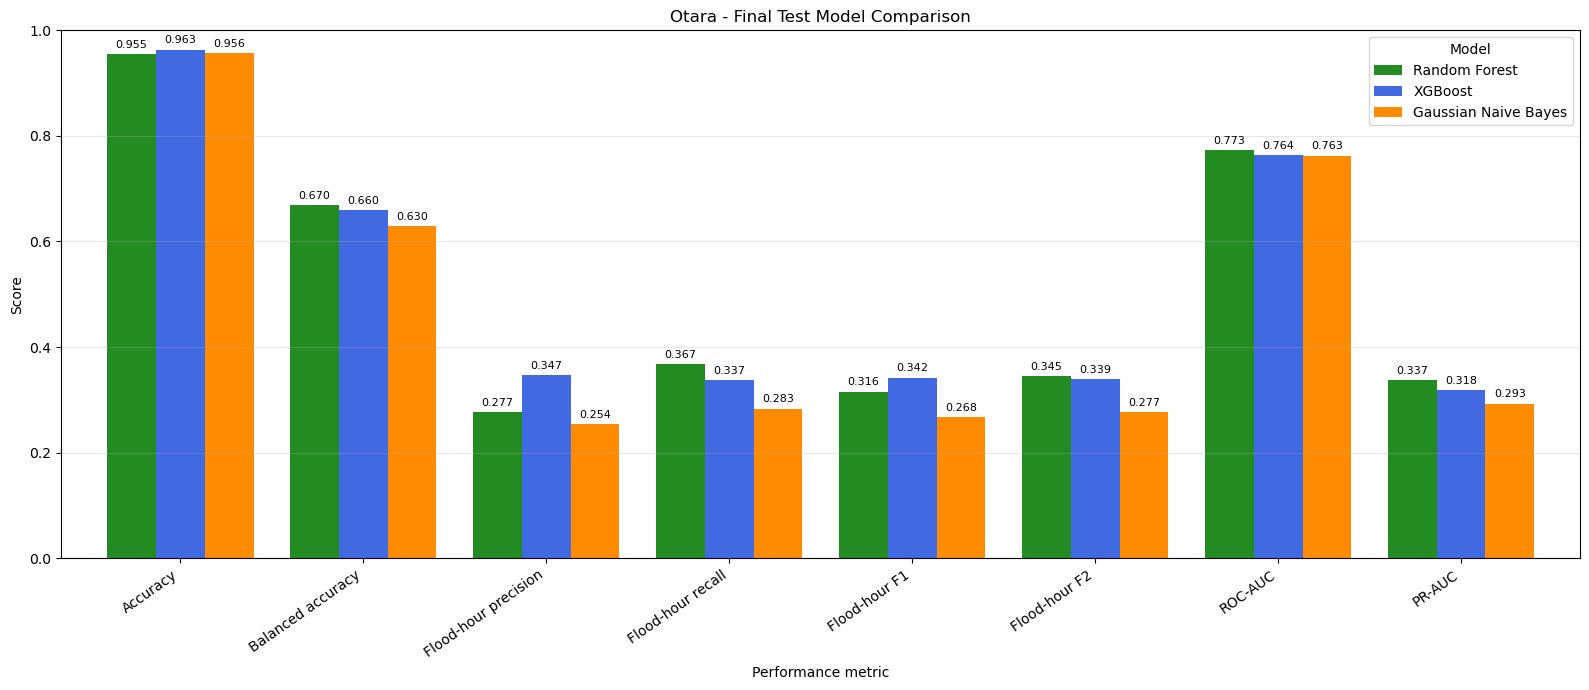

In [65]:
# OTARA FINAL TEST PERFORMANCE COMPARISON GRAPH

comparison_metrics = [
    "Accuracy",
    "Balanced accuracy",
    "Flood-hour precision",
    "Flood-hour recall",
    "Flood-hour F1",
    "Flood-hour F2",
    "ROC-AUC",
    "PR-AUC"
]

otara_comparison_plot = (
    otara_three_model_test_comparison
    .loc[comparison_metrics]
    .astype(float)
)

ax = otara_comparison_plot.plot(
    kind="bar",
    figsize=(16, 7),
    width=0.8,
    color=["forestgreen", "royalblue", "darkorange"]
)

ax.set_title("Otara - Final Test Model Comparison")
ax.set_xlabel("Performance metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=8)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

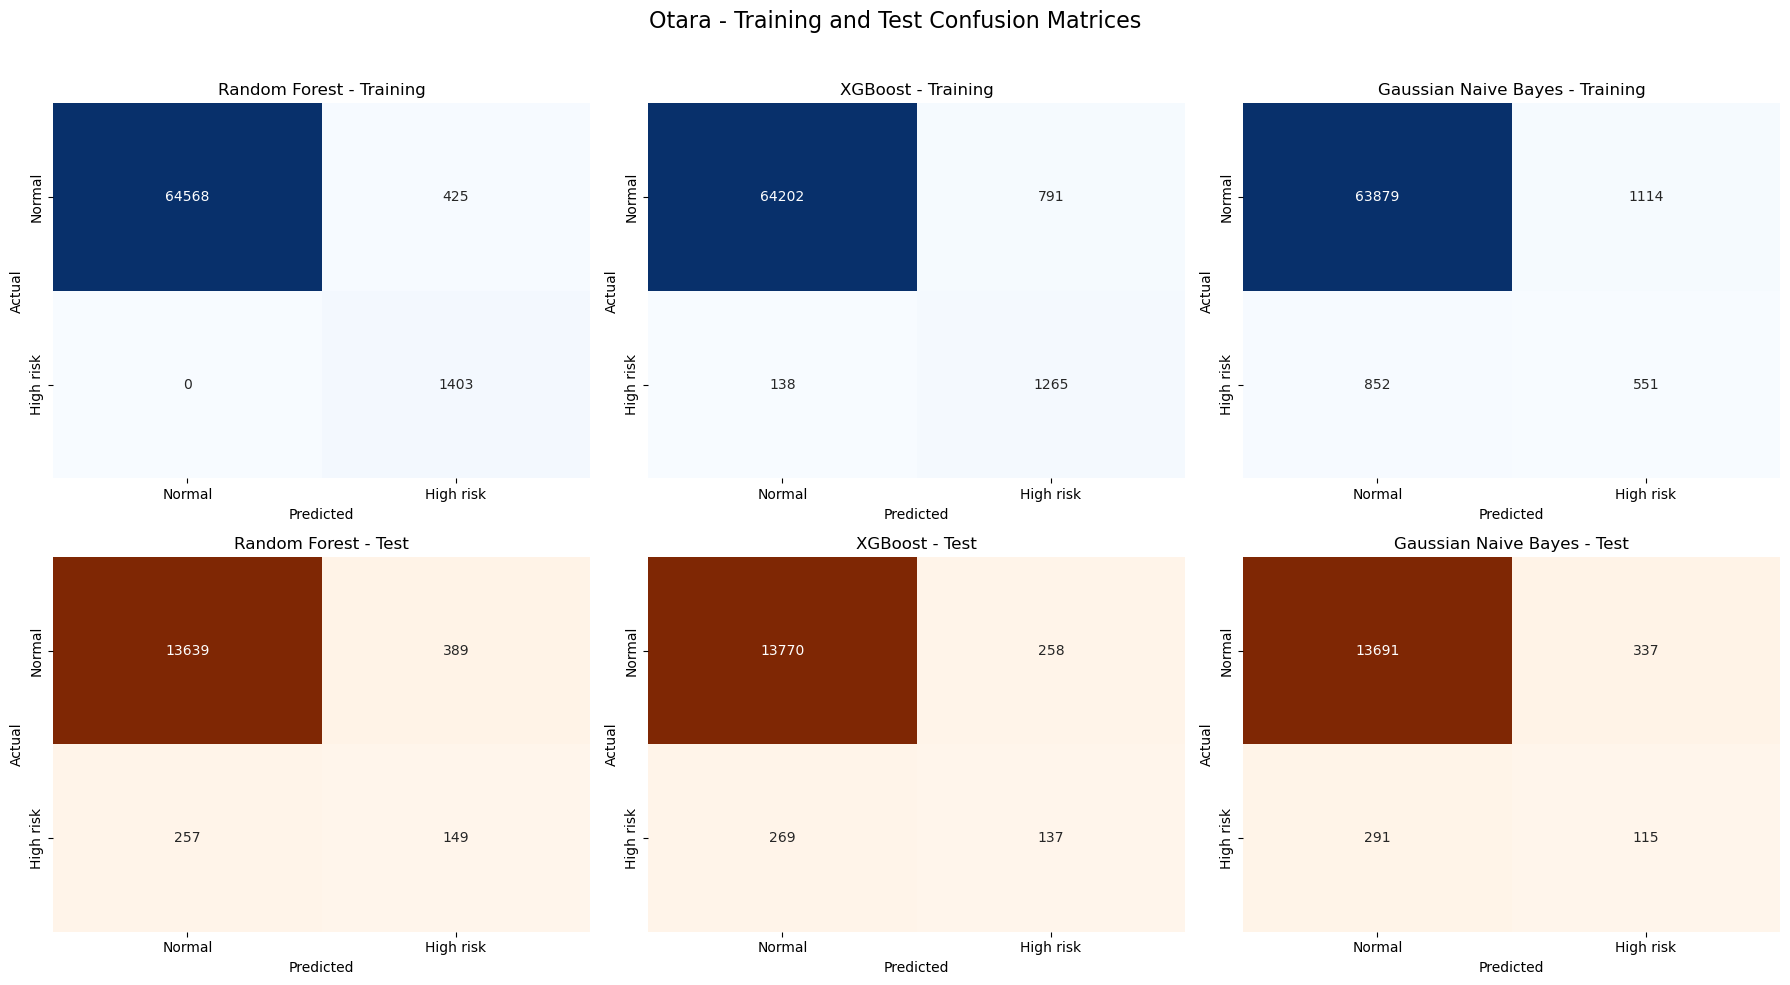

In [66]:
# OTARA TRAINING AND TEST CONFUSION MATRICES FOR ALL THREE MODELS

random_forest_training_probability = (
    random_forest_model.predict_proba(X_train)[:, 1]
)
random_forest_training_prediction = (
    random_forest_training_probability >= rf_best_f2_threshold
).astype(int)

xgboost_training_probability = (
    xgboost_model.predict_proba(X_train)[:, 1]
)
xgboost_training_prediction = (
    xgboost_training_probability >= xgboost_selected_threshold
).astype(int)

training_predictions = {
    "Random Forest": random_forest_training_prediction,
    "XGBoost": xgboost_training_prediction,
    "Gaussian Naive Bayes": training_prediction_nb
}

test_predictions_by_model = {
    "Random Forest": random_forest_test_prediction,
    "XGBoost": xgboost_test_prediction,
    "Gaussian Naive Bayes": test_prediction_nb
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for column, model_name in enumerate(training_predictions):
    training_matrix = confusion_matrix(
        y_train,
        training_predictions[model_name],
        labels=[0, 1]
    )

    test_matrix = confusion_matrix(
        y_test,
        test_predictions_by_model[model_name],
        labels=[0, 1]
    )

    sns.heatmap(
        training_matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Normal", "High risk"],
        yticklabels=["Normal", "High risk"],
        ax=axes[0, column]
    )
    axes[0, column].set_title(f"{model_name} - Training")
    axes[0, column].set_xlabel("Predicted")
    axes[0, column].set_ylabel("Actual")

    sns.heatmap(
        test_matrix,
        annot=True,
        fmt="d",
        cmap="Oranges",
        cbar=False,
        xticklabels=["Normal", "High risk"],
        yticklabels=["Normal", "High risk"],
        ax=axes[1, column]
    )
    axes[1, column].set_title(f"{model_name} - Test")
    axes[1, column].set_xlabel("Predicted")
    axes[1, column].set_ylabel("Actual")

fig.suptitle(
    "Otara - Training and Test Confusion Matrices",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

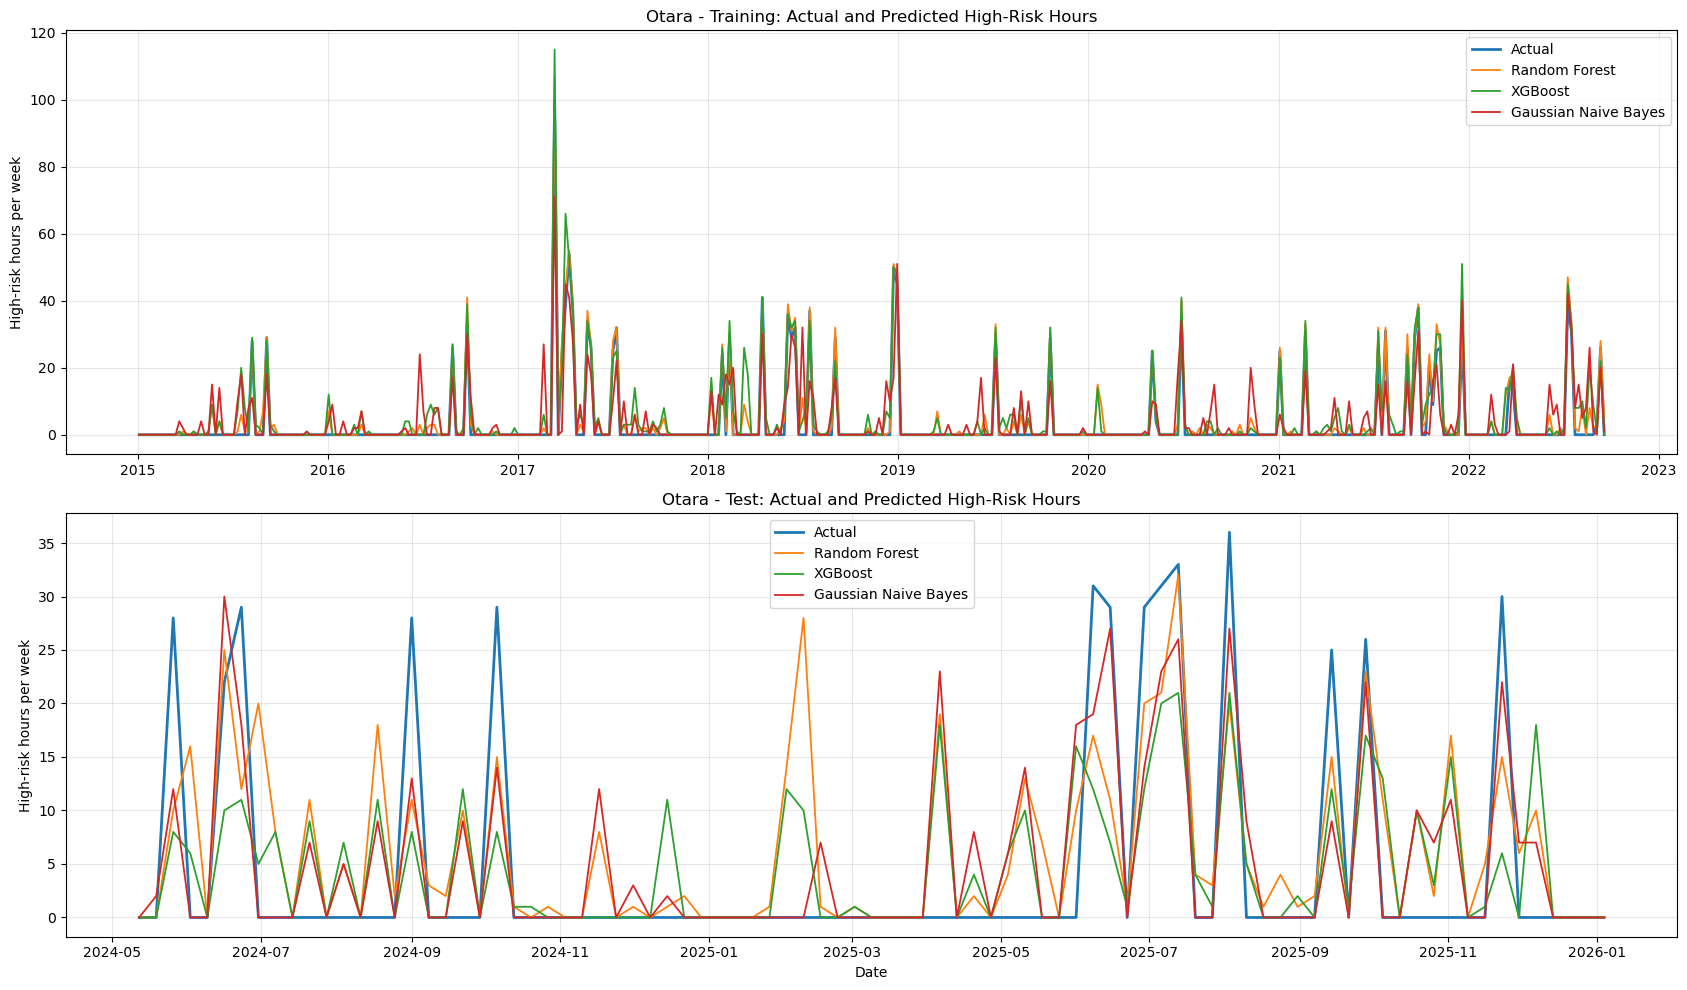

In [67]:
# OTARA WEEKLY ACTUAL VERSUS PREDICTED HIGH-RISK HOURS
# ALL THREE MODELS

otara_training_model_predictions = pd.DataFrame({
    "timestamp": pd.to_datetime(train_data["timestamp"]),
    "Actual": y_train.to_numpy(),
    "Random Forest": random_forest_training_prediction,
    "XGBoost": xgboost_training_prediction,
    "Gaussian Naive Bayes": training_prediction_nb
}).set_index("timestamp").resample("W").sum()

otara_test_model_predictions = pd.DataFrame({
    "timestamp": pd.to_datetime(test_data["timestamp"]),
    "Actual": y_test.to_numpy(),
    "Random Forest": random_forest_test_prediction,
    "XGBoost": xgboost_test_prediction,
    "Gaussian Naive Bayes": test_prediction_nb
}).set_index("timestamp").resample("W").sum()

fig, axes = plt.subplots(2, 1, figsize=(17, 10))

for column in otara_training_model_predictions.columns:
    axes[0].plot(
        otara_training_model_predictions.index,
        otara_training_model_predictions[column],
        label=column,
        linewidth=2 if column == "Actual" else 1.3
    )

axes[0].set_title(
    "Otara - Training: Actual and Predicted High-Risk Hours"
)
axes[0].set_ylabel("High-risk hours per week")
axes[0].legend()
axes[0].grid(alpha=0.3)

for column in otara_test_model_predictions.columns:
    axes[1].plot(
        otara_test_model_predictions.index,
        otara_test_model_predictions[column],
        label=column,
        linewidth=2 if column == "Actual" else 1.3
    )

axes[1].set_title(
    "Otara - Test: Actual and Predicted High-Risk Hours"
)
axes[1].set_xlabel("Date")
axes[1].set_ylabel("High-risk hours per week")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [68]:
# OTARA EVENT-LEVEL AND ALERT-EPISODE COMPARISON
# ALL THREE MODELS

def evaluate_model_episodes(
    model_name,
    probabilities,
    predictions
):
    diagnostics = pd.DataFrame({
        "timestamp": pd.to_datetime(test_data["timestamp"]),
        "actual_risk": y_test.to_numpy(),
        "risk_probability": probabilities,
        "predicted_risk": predictions
    }).sort_values("timestamp").reset_index(drop=True)

    continuous_from_previous = (
        diagnostics["timestamp"].diff() == pd.Timedelta(hours=1)
    )

    actual_positive = diagnostics["actual_risk"].eq(1)

    event_start = (
        actual_positive
        & (
            ~actual_positive.shift(fill_value=False)
            | ~continuous_from_previous
        )
    )

    event_numbers = event_start.cumsum()

    diagnostics["event_id"] = np.where(
        actual_positive,
        event_numbers,
        np.nan
    )

    event_results = (
        diagnostics[diagnostics["event_id"].notna()]
        .groupby("event_id")
        .agg(
            event_start=("timestamp", "min"),
            event_end=("timestamp", "max"),
            event_hours=("actual_risk", "size"),
            detected_hours=("predicted_risk", "sum"),
            maximum_score=("risk_probability", "max"),
            mean_score=("risk_probability", "mean")
        )
        .reset_index()
    )

    event_results["event_detected"] = (
        event_results["detected_hours"] > 0
    )

    event_results["hourly_detection_percentage"] = (
        event_results["detected_hours"]
        / event_results["event_hours"]
        * 100
    )

    predicted_positive = diagnostics["predicted_risk"].eq(1)

    alert_start = (
        predicted_positive
        & (
            ~predicted_positive.shift(fill_value=False)
            | ~continuous_from_previous
        )
    )

    alert_numbers = alert_start.cumsum()

    diagnostics["alert_id"] = np.where(
        predicted_positive,
        alert_numbers,
        np.nan
    )

    alert_results = (
        diagnostics[diagnostics["alert_id"].notna()]
        .groupby("alert_id")
        .agg(
            alert_start=("timestamp", "min"),
            alert_end=("timestamp", "max"),
            alert_hours=("predicted_risk", "size"),
            actual_risk_hours=("actual_risk", "sum"),
            maximum_score=("risk_probability", "max"),
            mean_score=("risk_probability", "mean")
        )
        .reset_index()
    )

    alert_results["associated_with_risk"] = (
        alert_results["actual_risk_hours"] > 0
    )

    total_events = len(event_results)
    detected_events = int(event_results["event_detected"].sum())

    total_alerts = len(alert_results)
    useful_alerts = int(
        alert_results["associated_with_risk"].sum()
    )
    false_alerts = total_alerts - useful_alerts

    summary = {
        "Model": model_name,
        "Events detected": detected_events,
        "Total actual events": total_events,
        "Event-level recall": (
            detected_events / total_events
            if total_events > 0 else np.nan
        ),
        "Total alert episodes": total_alerts,
        "Useful alert episodes": useful_alerts,
        "False alert episodes": false_alerts,
        "Alert-episode precision": (
            useful_alerts / total_alerts
            if total_alerts > 0 else np.nan
        )
    }

    return diagnostics, event_results, alert_results, summary


(
    otara_rf_test_diagnostics,
    otara_rf_event_results,
    otara_rf_alert_results,
    otara_rf_episode_summary
) = evaluate_model_episodes(
    "Random Forest",
    random_forest_test_probability,
    random_forest_test_prediction
)

(
    otara_xgb_test_diagnostics,
    otara_xgb_event_results,
    otara_xgb_alert_results,
    otara_xgb_episode_summary
) = evaluate_model_episodes(
    "XGBoost",
    xgboost_test_probability,
    xgboost_test_prediction
)

(
    otara_nb_test_diagnostics,
    otara_naive_bayes_event_results,
    otara_naive_bayes_alert_results,
    otara_nb_episode_summary
) = evaluate_model_episodes(
    "Gaussian Naive Bayes",
    test_probability_nb,
    test_prediction_nb
)

otara_three_model_episode_comparison = pd.DataFrame([
    otara_rf_episode_summary,
    otara_xgb_episode_summary,
    otara_nb_episode_summary
]).set_index("Model").T

print("OTARA EVENT AND ALERT EPISODE COMPARISON")
display(otara_three_model_episode_comparison.round(4))

OTARA EVENT AND ALERT EPISODE COMPARISON


Model,Random Forest,XGBoost,Gaussian Naive Bayes
Events detected,14.0000,14.0000,14.00
Total actual events,14.0000,14.0000,14.00
Event-level recall,1.0000,1.0000,1.00
Total alert episodes,140.0000,107.0000,50.00
Useful alert episodes,18.0000,22.0000,16.00
False alert episodes,122.0000,85.0000,34.00
Alert-episode precision,0.1286,0.2056,0.32


In [69]:
# OTARA COMPLETE FINAL MODEL COMPARISON

otara_complete_model_comparison = pd.concat([
    otara_three_model_test_comparison,
    otara_three_model_episode_comparison
])

print("OTARA COMPLETE FINAL TEST MODEL COMPARISON")
display(otara_complete_model_comparison.round(4))

print("Recommended Otara model: Random Forest")
print(
    "Reason: Random Forest achieved the highest flood-hour recall, "
    "F2 score, ROC-AUC and PR-AUC while detecting all 14 flood-risk events."
)

print(
    "\nOperational note: Gaussian Naive Bayes generated the fewest "
    "alert episodes and had the highest alert-episode precision."
)

OTARA COMPLETE FINAL TEST MODEL COMPARISON


Model,Random Forest,XGBoost,Gaussian Naive Bayes
Probability threshold,0.1580,0.7530,0.0198
Accuracy,0.9552,0.9635,0.9565
Balanced accuracy,0.6696,0.6595,0.6296
Flood-hour precision,0.2770,0.3468,0.2544
Flood-hour recall,0.3670,0.3374,0.2833
Flood-hour F1,0.3157,0.3421,0.2681
Flood-hour F2,0.3446,0.3393,0.2770
ROC-AUC,0.7732,0.7640,0.7626
PR-AUC,0.3374,0.3180,0.2928
True positives,149.0000,137.0000,115.0000


Recommended Otara model: Random Forest
Reason: Random Forest achieved the highest flood-hour recall, F2 score, ROC-AUC and PR-AUC while detecting all 14 flood-risk events.

Operational note: Gaussian Naive Bayes generated the fewest alert episodes and had the highest alert-episode precision.


In [70]:
# EXPORT OTARA NAIVE BAYES AND MODEL COMPARISON OUTPUTS

from pathlib import Path
import joblib

output_directory = (
    Path.home() / "Downloads" / "Otara_Model_Outputs"
)
output_directory.mkdir(parents=True, exist_ok=True)

otara_naive_bayes_tuning_results.to_csv(
    output_directory / "otara_naive_bayes_tuning_results.csv",
    index=False
)

otara_naive_bayes_validation_results.to_csv(
    output_directory / "otara_naive_bayes_validation_results.csv",
    index=False
)

otara_naive_bayes_test_results.to_csv(
    output_directory / "otara_naive_bayes_test_results.csv",
    index=False
)

otara_naive_bayes_test_predictions.to_csv(
    output_directory / "otara_naive_bayes_test_predictions.csv",
    index=False
)

otara_naive_bayes_event_results.to_csv(
    output_directory / "otara_naive_bayes_event_results.csv",
    index=False
)

otara_naive_bayes_alert_results.to_csv(
    output_directory / "otara_naive_bayes_alert_results.csv",
    index=False
)

otara_naive_bayes_train_test_comparison.to_csv(
    output_directory /
    "otara_naive_bayes_train_test_comparison.csv"
)

otara_xgboost_test_results.to_csv(
    output_directory / "otara_xgboost_test_results.csv",
    index=False
)

otara_three_model_test_comparison.to_csv(
    output_directory / "otara_three_model_test_comparison.csv"
)

otara_three_model_episode_comparison.to_csv(
    output_directory / "otara_three_model_episode_comparison.csv"
)

otara_complete_model_comparison.to_csv(
    output_directory / "otara_complete_model_comparison.csv"
)

otara_training_model_predictions.to_csv(
    output_directory / "otara_training_model_predictions.csv"
)

otara_test_model_predictions.to_csv(
    output_directory / "otara_test_model_predictions.csv"
)

joblib.dump(
    otara_naive_bayes_model,
    output_directory / "otara_naive_bayes_model.joblib"
)

print("Otara Naive Bayes and comparison outputs saved to:")
print(output_directory)

print("\nSaved files:")
for saved_file in sorted(output_directory.iterdir()):
    print("-", saved_file.name)

Otara Naive Bayes and comparison outputs saved to:
C:\Users\kgeet\Downloads\Otara_Model_Outputs

Saved files:
- otara_complete_model_comparison.csv
- otara_naive_bayes_alert_results.csv
- otara_naive_bayes_event_results.csv
- otara_naive_bayes_model.joblib
- otara_naive_bayes_test_predictions.csv
- otara_naive_bayes_test_results.csv
- otara_naive_bayes_train_test_comparison.csv
- otara_naive_bayes_tuning_results.csv
- otara_naive_bayes_validation_results.csv
- otara_test_model_predictions.csv
- otara_three_model_episode_comparison.csv
- otara_three_model_test_comparison.csv
- otara_training_model_predictions.csv
- otara_xgboost_test_results.csv
